<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 2 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: George Lucas dos Santos Bastos

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://colab.research.google.com/drive/1crNiA-UxuBaayuDT6K0kujP44wDCLsBV#scrollTo=-fBOGCLPkasu)

**LINK PARA SEU GITHUB DO PROJETO COMPLETO - OBRIGATÓRIO (0.5 ponto)**: [Aqui](https://github.com/GeorgeLucassb/TCC-UWine-Parte-2-George-Lucas)

**LINK PARA SEU PRÓPRIO VÍDEO NO YOUTUBE - OBRIGATÓRIO (0.5 ponto):** [Aqui](https://)

# **Cenário Fictício**:

Prezados(as) alunos(as),

É ótimo que você como **Consultor** ( ***Data Science Consultant*** ) do **Projeto Data Science** tenha chegado no **Workflow - Parte 2: Aprendizado de Máquina** (*Machine Learnning*). A *Incrível Biblioteca*:

<center>

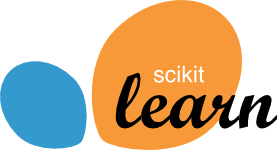

<center>

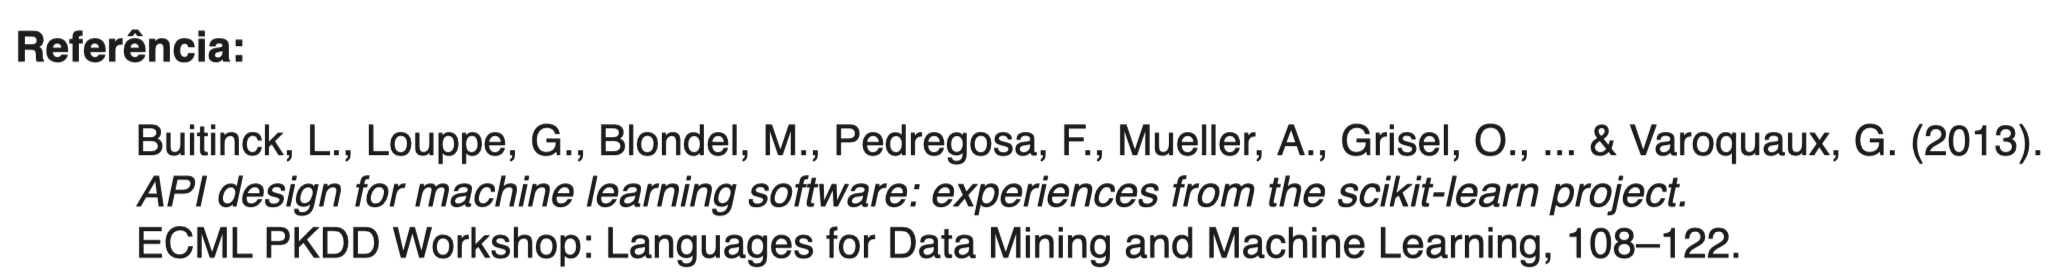

Neste etapa, você irá usar conjuntos (vários) que virão do **Workflow - Parte1**, a saber:

*   Conjunto de Treinamento: ***train***
*   Conjunto de Validação: ***validation***
*   Conjunto de Teste: ***test***

<center>

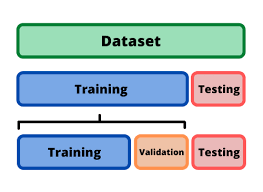

Ou seja:

<center>

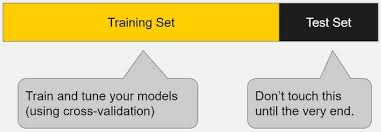


Com todas as Análises e *Insights* (**Estatistica Descritiva,** **Testes de Hipóteses** e os **Métodos Quantitativos**) que irão garatir que temos conjuntos com Qualidade (***Best Quality Analytics***) e que são ótimas amostras em relação a população ratificando justamente a importância da Parte 1 do projeto.

<center>

**EXCELENTE!!! Agora podemos ir mais longe no Universo Python!** 🚀🚀🚀

</center>

Podemos praticar as técnicas mais avançadas do **Aprendizado de Máquina** (*Machine Learnning*) e criarmos aprendizes dos seguintes modelos, a saber:

*   REGRESSOR: Modelo de Regressão: [Regression](https://scikit-learn.org/stable/supervised_learning.html)
*   CLUSTERIZADOR: Modelo de Agrupamento: [Clustering](https://scikit-learn.org/stable/modules/clustering.html)
*   CLASSIFICADOR: Modelo de Classificação:  [Classification](https://scikit-learn.org/stable/supervised_learning.html)

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do projeto, adotaremos um **Fluxo de Projeto (Ciclo de Vida)** composto pela atividades estabelecidas no **Workflow - Parte 2**, conforme a seguir:

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import statsmodels.api as sm
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import (AdaBoostClassifier, HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (adjusted_rand_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support, silhouette_samples, silhouette_score)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multitest import multipletests
from threadpoolctl import threadpool_limits
from IPython.display import HTML, Markdown, display

SEED = 42  # semente única: todos os sorteios do notebook partem dela
threadpool_limits(1, user_api='blas')  # matrizes pequenas: uma thread de BLAS evita disputa com o OpenMP do scikit-learn
N_IDEAL = 30_100  # tamanho ideal da amostra, definido na A1.1 da Parte 1

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 100)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'figure.constrained_layout.use': True,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7',
    'grid.color': '#e1e0d9',
    'grid.linewidth': 0.7,
    'legend.frameon': False,
})

# Nomes de colunas usados o tempo todo
TOTAL, RENDA, PLANO = 'TOTAL (R$)', 'RENDA BRUTO (R$)', 'TIPO DA CONTA'
OPINIAO, NOTA = 'OPINIÃO DO CLIENTE', 'NOTA DE SATISFAÇÃO (%)'
CADASTRO = ['REGIÃO', 'SEXO', 'ESTADO CIVIL', 'DEPENDENTES']

# Cada plano tem sempre a mesma cor em todos os gráficos
PLANOS = ['ESSENTIAL', 'VIP', 'PRIME']
CORES_PLANO = {'ESSENTIAL': '#2a78d6', 'VIP': '#eb6834', 'PRIME': '#1baf7a'}

# Treino e validação mantêm as cores da SAMPLE 1 e da SAMPLE 2 na Parte 1
CONJUNTOS = ['Treino', 'Validação', 'Teste']
CORES_CONJUNTO = {'Treino': '#4a3aa7', 'Validação': '#eda100', 'Teste': '#e34948', 'População': '#898781'}
CINZA = '#52514e'


def num(valor, casas=0):
    """Formata um número no padrão brasileiro: num(-1234.5, 1) -> '−1.234,5'."""
    texto = f'{abs(valor):,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')
    negativo = valor < 0 and texto.strip('0,.') != ''
    return ('−' if negativo else '') + texto


def brl(valor, casas=2):
    """Formata um valor em reais: -1234.5 -> '−R$ 1.234,50'."""
    texto = num(valor, casas)
    return '−R$ ' + texto[1:] if texto.startswith('−') else 'R$ ' + texto


def pct(fracao, casas=1):
    """Formata uma fração como porcentagem: 0.1234 -> '12,3%'."""
    return num(100 * fracao, casas) + '%'


def fmt_p(p):
    """Formata um p-valor; abaixo de 0,001 escreve '< 0,001'."""
    return '< 0,001' if p < 0.001 else num(p, 3)


def tabela(df, casas=2, indice=True, titulo=None):
    """Exibe uma tabela com números no padrão brasileiro.

    Usa `casas` para decimais e mostra `titulo` acima da tabela, se informado.
    Valores ausentes aparecem como 'n/a' (não se aplica).
    """
    def formatar(valor):
        if isinstance(valor, (bool, np.bool_)):
            return valor
        if isinstance(valor, (int, np.integer)):
            return num(valor)
        if isinstance(valor, (float, np.floating)):
            return 'n/a' if np.isnan(valor) else num(valor, casas)
        return valor

    if titulo:
        display(Markdown('**' + titulo.replace('$', r'\$') + '**'))
    display(HTML(df.map(formatar).to_html(index=indice, border=0)))
    display(Markdown('&nbsp;'))


def eixo_reais(ax, eixo='y', marcas_log=(1, 2, 5)):
    """Escreve os rótulos de um eixo em reais; em escala log, marca 1, 2 e 5 de cada potência de 10."""
    alvo = ax.yaxis if eixo == 'y' else ax.xaxis
    if (ax.get_yscale() if eixo == 'y' else ax.get_xscale()) == 'log':
        alvo.set_major_locator(mticker.LogLocator(base=10, subs=marcas_log))
        alvo.set_minor_formatter(mticker.NullFormatter())
    alvo.set_major_formatter(mticker.FuncFormatter(lambda v, _: brl(v, 0)))


def eixo_milhar(ax, eixo='x'):
    """Escreve os rótulos de um eixo com separador de milhar (5.000)."""
    formato = mticker.FuncFormatter(lambda v, _: num(v))
    (ax.xaxis if eixo == 'x' else ax.yaxis).set_major_formatter(formato)


def mostrar(fig):
    """Exibe a figura e usa vírgula decimal nos eixos com formato padrão.
    """
    fig.draw_without_rendering()  # lê as marcas já no layout final
    for ax in fig.axes:
        for alvo in (ax.xaxis, ax.yaxis):
            if type(alvo.get_major_formatter()) is mticker.ScalarFormatter:
                marcas = np.asarray(alvo.get_ticklocs())
                casas = next((c for c in range(6) if np.allclose(np.round(marcas, c), marcas)), 6)
                alvo.set_major_locator(mticker.FixedLocator(marcas))
                alvo.set_major_formatter(mticker.FuncFormatter(lambda v, _, c=casas: num(v, c)))
    plt.show()


## Load dos Datasets:

In [ ]:
# Base da Parte 1 (table26): fica ao lado do notebook ou na pasta dados/ do projeto
arquivo_base = next((p for p in ['table26.csv', '../dados/table26.csv'] if os.path.exists(p)), 'table26.csv')
table26 = pd.read_csv(arquivo_base, index_col=0, encoding='utf-8')
table26.shape

(1120000, 23)

## Escopo da análise

A Parte 2 usa os resultados da Parte 1. O tamanho ideal de 30.100 notas fiscais define os conjuntos de treino, validação e teste, todos com a alocação de Neyman da Parte 1. O regressor e o classificador são ajustados no treino; o clusterizador, em treino e validação juntos, como pede o roteiro. A validação serve para comparar modelos e escolher parâmetros, e o teste só entra na avaliação final, sem influenciar nenhuma escolha. Uma quarta amostra, com a composição dos planos na base, representa a população nos passos de teste com dados da população.

Para cada modelo, definimos o momento em que ele seria usado. Variáveis que só existem depois desse momento, ou que repetem o alvo, ficam de fora; essas decisões são testadas na etapa de ETL de cada atividade.

No regressor e no classificador, os intervalos de confiança de 95% do treino vêm da validação cruzada com 10 dobras e do bootstrap das previsões fora da dobra. Na validação, o modelo ajustado no treino não é reajustado: o intervalo vem da divisão da validação em 10 partes e do bootstrap das previsões, com 2.000 reamostras.

## Preparação dos conjuntos

Repetimos as verificações da base feitas na Parte 1 e sorteamos os conjuntos com a mesma lógica de sorteio. Treino e validação reproduzem a SAMPLE 1 e a SAMPLE 2 da Parte 1, porque usam o mesmo gerador de números aleatórios, na mesma ordem. O teste é o sorteio seguinte desse gerador, feito nas notas que sobraram. Como os sorteios saem agrupados por plano, embaralhamos depois a ordem das linhas de cada conjunto, com outro gerador.

A amostra da população não pode ser um sorteio simples entre as notas restantes. As três amostras de Neyman retiram muitas notas do PRIME, e o restante da base fica com uma proporção de PRIME menor que a da base completa. Por isso, essa amostra usa alocação proporcional, com os pesos dos planos na base.

In [ ]:
QUIMICA = [c for c in table26.columns if c.startswith('MEAN:')]


def preparar_base(df):
    """Confere ausentes, duplicatas, valores em reais e medidas químicas.

    Retorna uma cópia da base com os tipos ajustados, a marca QUIMICA_INVALIDA
    e uma tabela das verificações. Não remove nem imputa registros.
    """
    base = df.copy()
    registro = []

    def anotar(verificacao, resultado):
        registro.append({'Verificação': verificacao, 'Resultado': resultado})

    anotar('Valores ausentes', f'{num(base.isna().sum().sum())} células vazias')
    anotar('Linhas duplicadas', f'{num(base.duplicated().sum())} linhas repetidas')
    anotar('Nota fiscal como chave', f'{num(base["NOTA FISCAL"].duplicated().sum())} notas repetidas')

    for coluna in ['REGIÃO', 'SEXO', 'ESTADO CIVIL']:
        base[coluna] = base[coluna].astype('category')
    anotar('Tipos de dado', 'região, sexo e estado civil viraram categorias')

    anotar('Valores em reais',
           f'TOTAL de {brl(base[TOTAL].min())} a {brl(base[TOTAL].max())}; '
           f'renda de {brl(base[RENDA].min())} a {brl(base[RENDA].max())}')

    negativos = base[QUIMICA] < 0
    base['QUIMICA_INVALIDA'] = negativos.any(axis=1)
    anotar('Química dos vinhos (13 colunas)',
           f'{num(negativos.to_numpy().sum())} valores negativos em {num(base["QUIMICA_INVALIDA"].sum())} '
           f'linhas ({pct(base["QUIMICA_INVALIDA"].mean())})')

    fixa = base[NOTA].eq(68.68)
    anotar('Nota de satisfação (%)',
           f'{pct(fixa.mean())} das linhas valem 68,68')

    # Regras que precisam valer para seguir adiante
    assert base['NOTA FISCAL'].is_unique
    assert base[TOTAL].gt(0).all() and base[RENDA].gt(0).all()
    assert set(base[PLANO].unique()) == set(PLANOS)

    return base, pd.DataFrame(registro)

In [ ]:
def pesos_dos_planos(df):
    """Peso de cada plano na base (W_h), na ordem ESSENTIAL, VIP, PRIME."""
    return df[PLANO].value_counts(normalize=True).reindex(PLANOS)


def arredondar_alocacao(bruto, n):
    """Arredonda pelo maior resto, para que a alocação some exatamente n."""
    alocacao = np.floor(bruto).astype(int)
    faltam = int(n - alocacao.sum())
    maiores_restos = (bruto - alocacao).sort_values(ascending=False).index[:faltam]
    alocacao.loc[maiores_restos] += 1
    return alocacao


def alocacao_neyman(df, n, valor=TOTAL):
    """Divide n notas entre os planos pela alocação de Neyman (n_h proporcional a W_h x S_h)."""
    pesos = pesos_dos_planos(df)
    desvios = df.groupby(PLANO)[valor].std().reindex(PLANOS)
    return arredondar_alocacao(n * (pesos * desvios) / (pesos * desvios).sum(), n)


def alocacao_proporcional(df, n):
    """Divide n notas entre os planos na proporção em que aparecem na base."""
    return arredondar_alocacao(n * pesos_dos_planos(df), n)


def amostra_estratificada(df, alocacao, rng):
    """Sorteia, sem reposição, alocacao[h] notas fiscais de cada plano h."""
    partes = [df[df[PLANO] == plano].sample(n=int(n_h), random_state=rng)
              for plano, n_h in alocacao.items()]
    return pd.concat(partes)


def montar_conjuntos(base, n):
    """Sorteia treino, validação e teste com a alocação de Neyman e a amostra da população.

    Usa o gerador da A1.3 da Parte 1, então os dois primeiros sorteios repetem a SAMPLE 1
    e a SAMPLE 2. Cada sorteio é feito nas notas que sobraram dos anteriores. A amostra da
    população tem alocação proporcional aos pesos dos planos na base.
    Por fim, embaralha a ordem das linhas, que os sorteios deixam agrupadas por plano.
    Retorna os conjuntos e as notas por plano que restavam antes da amostra da população.
    """
    rng = np.random.default_rng(SEED + 1)
    neyman = alocacao_neyman(base, n)
    conjuntos, restante = {}, base
    for nome in CONJUNTOS:
        conjuntos[nome] = amostra_estratificada(restante, neyman, rng)
        restante = restante.drop(index=conjuntos[nome].index)
    conjuntos['População'] = amostra_estratificada(restante, alocacao_proporcional(base, n), rng)
    ordem = np.random.default_rng(SEED + 2)  # gerador próprio: o embaralhamento não altera os sorteios
    conjuntos = {nome: df.sample(frac=1, random_state=ordem) for nome, df in conjuntos.items()}
    return conjuntos, restante[PLANO].value_counts().reindex(PLANOS)


def validar_conjuntos(conjuntos, base, restante_por_plano):
    """Confere composição, sobreposição e semelhança dos conjuntos.

    Compara treino, validação e teste dentro de cada plano, para TOTAL e renda
    (Kruskal-Wallis e Anderson-Darling k-amostras), e no cadastro (qui-quadrado).
    Retorna as tabelas de composição, médias, testes e cadastro e o número de notas em comum.
    """
    def formatar_p_ad(p):
        """O SciPy limita o p-valor do Anderson-Darling k-amostras entre 0,001 e 0,25."""
        return '≥ 0,25' if p >= 0.25 else ('≤ 0,001' if p <= 0.001 else num(p, 3))

    nomes = [*CONJUNTOS, 'População']
    em_comum = sum(len(conjuntos[a].index.intersection(conjuntos[b].index))
                   for i, a in enumerate(nomes) for b in nomes[i + 1:])

    pesos_base = pesos_dos_planos(base)
    contagens = {nome: conjuntos[nome][PLANO].value_counts().reindex(PLANOS) for nome in nomes}
    contagens['Restante da base, antes da população'] = restante_por_plano
    contagens['Base completa'] = base[PLANO].value_counts().reindex(PLANOS)
    contagens = pd.DataFrame(contagens).T
    composicao = pd.concat([contagens, (100 * contagens.div(contagens.sum(axis=1), axis=0)).add_suffix(' (%)')], axis=1)
    composicao.insert(0, 'Notas', contagens.sum(axis=1))
    composicao = composicao.rename_axis(index='Conjunto', columns=None)

    medias = pd.DataFrame({nome: conjuntos[nome].groupby(PLANO)[TOTAL].mean() for nome in nomes}).reindex(PLANOS)
    medias['Base completa'] = base.groupby(PLANO)[TOTAL].mean()
    medias.loc['Geral, ponderada pelos pesos da base'] = medias.mul(pesos_base, axis=0).sum()
    medias = medias.add_suffix(' (R$)').rename_axis('Plano')

    linhas = []
    for variavel, rotulo in [(TOTAL, 'TOTAL'), (RENDA, 'Renda')]:
        for plano in PLANOS:
            grupos = [conjuntos[nome].loc[conjuntos[nome][PLANO] == plano, variavel].to_numpy()
                      for nome in CONJUNTOS]
            kw = stats.kruskal(*grupos)
            with warnings.catch_warnings():
                # O SciPy limita o p-valor do AD k-amostras entre 0,001 e 0,25 e avisa quando isso ocorre
                warnings.filterwarnings('ignore', message='p-value (capped|floored)')
                ad = stats.anderson_ksamp(grupos, variant='midrank')
            linhas.append({'Variável': rotulo, 'Plano': plano, 'Kruskal-Wallis (H)': kw.statistic,
                           'p-valor KW': kw.pvalue, 'Anderson-Darling (A²)': ad.statistic, 'p-valor AD': ad.pvalue})
    testes = pd.DataFrame(linhas)
    testes['Rejeita H0 a 5%? (KW / AD)'] = [f"{'sim' if p_kw < 0.05 else 'não'} / {'sim' if p_ad < 0.05 else 'não'}"
                                            for p_kw, p_ad in zip(testes['p-valor KW'], testes['p-valor AD'])]

    juntos = pd.concat({nome: conjuntos[nome][CADASTRO] for nome in CONJUNTOS}, names=['Conjunto'])
    linhas = []
    for coluna in CADASTRO:
        cruzamento = pd.crosstab(juntos.index.get_level_values('Conjunto'), juntos[coluna])
        r = stats.chi2_contingency(cruzamento)
        linhas.append({'Variável': coluna, 'Qui-quadrado': r.statistic, 'Graus de liberdade': r.dof,
                       'p-valor': r.pvalue, 'Rejeita H0 a 5%?': 'sim' if r.pvalue < 0.05 else 'não'})
    cadastro = pd.DataFrame(linhas)

    tabela(composicao, casas=1, titulo=f'Composição dos conjuntos por plano (notas em comum entre conjuntos: {em_comum})')
    tabela(medias, titulo='Média do TOTAL por plano em cada conjunto')

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, plano in zip(axes, PLANOS):
        for nome, ls in zip(nomes, ['-', '--', ':', '-.']):
            v = np.sort(conjuntos[nome].loc[conjuntos[nome][PLANO] == plano, TOTAL].to_numpy())
            ax.step(v, np.arange(1, len(v) + 1) / len(v), where='post', color=CORES_CONJUNTO[nome],
                    ls=ls, lw=1.3, label=nome)
        ax.set(title=plano, xlabel='TOTAL da compra')
        eixo_reais(ax, 'x')
        ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
    axes[0].set_ylabel('Proporção acumulada')
    axes[0].legend(fontsize=8)
    mostrar(fig)

    tabela(testes.assign(**{'Kruskal-Wallis (H)': testes['Kruskal-Wallis (H)'].map(lambda v: num(v, 2)),
                            'p-valor KW': testes['p-valor KW'].map(fmt_p),
                            'Anderson-Darling (A²)': testes['Anderson-Darling (A²)'].map(lambda v: num(v, 2)),
                            'p-valor AD': testes['p-valor AD'].map(formatar_p_ad)}),
           indice=False, titulo='Treino, validação e teste têm a mesma distribuição dentro de cada plano? '
                                '(o A² do k-amostras é padronizado e pode ser negativo)')
    tabela(cadastro.assign(**{'p-valor': cadastro['p-valor'].map(fmt_p)}), indice=False,
           titulo='Treino, validação e teste têm a mesma composição de cadastro?')
    return {'composicao': composicao, 'medias': medias, 'testes': testes, 'cadastro': cadastro,
            'em_comum': em_comum}

In [ ]:
base, registro = preparar_base(table26)
tabela(registro, indice=False, titulo='Registro da preparação da base')

**Registro da preparação da base**

Verificação,Resultado
Valores ausentes,0 células vazias
Linhas duplicadas,0 linhas repetidas
Nota fiscal como chave,0 notas repetidas
Tipos de dado,"região, sexo e estado civil viraram categorias"
Valores em reais,"TOTAL de R$ 74,45 a R$ 5.520,96; renda de R$ 1.755,81 a R$ 32.216,42"
Química dos vinhos (13 colunas),"74.577 valores negativos em 72.665 linhas (6,5%)"
Nota de satisfação (%),"92,8% das linhas valem 68,68"


&nbsp;

**Conclusão**

A base é a mesma da Parte 1: 1.120.000 notas fiscais e 23 colunas, sem valores ausentes nem linhas duplicadas, e cada nota fiscal aparece uma única vez.

As medidas químicas continuam com valores negativos em 72.665 linhas (6,5%), e a nota de satisfação vale 68,68 em 92,8% das linhas. Essas duas questões voltam na escolha das variáveis de cada modelo.

*Load* dos dataset aqui, a saber:

*   Conjunto de Treinamento do **TAMANHO IDEAL**: ***train***
*   Conjunto de Validação do **TAMANHO IDEAL**: ***validation***
*   Conjunto de Teste do **TAMANHO IDEAL**: ***test***

Qual o "TAMANHO IDEAL" do conjunto:

*   Conjunto de Treinamento: **30.100 notas fiscais**
*   Conjunto de Validação: **30.100 notas fiscais**
*   Conjunto de Teste: **30.100 notas fiscais**

**Composição dos conjuntos por plano (notas em comum entre conjuntos: 0)**

,Notas,ESSENTIAL,VIP,PRIME,ESSENTIAL (%),VIP (%),PRIME (%)
Conjunto,,,,,,,
Treino,30.100,11.542,6.650,11.908,"38,3","22,1","39,6"
Validação,30.100,11.542,6.650,11.908,"38,3","22,1","39,6"
Teste,30.100,11.542,6.650,11.908,"38,3","22,1","39,6"
População,30.100,19.260,6.357,4.483,"64,0","21,1","14,9"
"Restante da base, antes da população",1.029.700,682.028,216.576,131.096,"66,2","21,0","12,7"
Base completa,1.120.000,716.654,236.526,166.820,"64,0","21,1","14,9"


&nbsp;

**Média do TOTAL por plano em cada conjunto**

,Treino (R$),Validação (R$),Teste (R$),População (R$),Base completa (R$)
Plano,,,,,
ESSENTIAL,"375,55","383,45","379,54","379,61","380,69"
VIP,"888,01","888,66","880,96","881,07","884,05"
PRIME,"2.278,17","2.278,22","2.266,55","2.295,69","2.283,61"
"Geral, ponderada pelos pesos da base","767,16","772,36","766,49","770,90","770,42"


&nbsp;

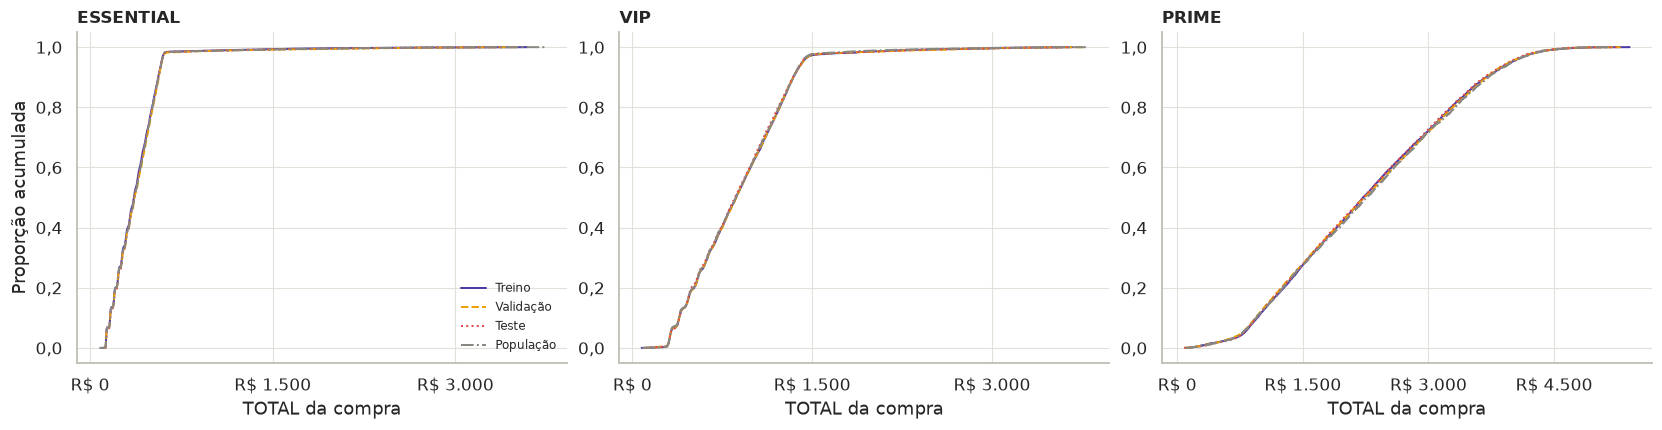

**Treino, validação e teste têm a mesma distribuição dentro de cada plano? (o A² do k-amostras é padronizado e pode ser negativo)**

Variável,Plano,Kruskal-Wallis (H),p-valor KW,Anderson-Darling (A²),p-valor AD,Rejeita H0 a 5%? (KW / AD)
TOTAL,ESSENTIAL,"6,79","0,034","2,62","0,024",sim / sim
TOTAL,VIP,"1,79","0,408","−0,68","≥ 0,25",não / não
TOTAL,PRIME,"0,92","0,632","0,16","≥ 0,25",não / não
Renda,ESSENTIAL,"0,57","0,751","−0,78","≥ 0,25",não / não
Renda,VIP,"4,78","0,092","1,02","0,135",não / não
Renda,PRIME,"3,50","0,174","2,11","0,042",não / sim


&nbsp;

**Treino, validação e teste têm a mesma composição de cadastro?**

Variável,Qui-quadrado,Graus de liberdade,p-valor,Rejeita H0 a 5%?
REGIÃO,"10,21",8,"0,251",não
SEXO,"2,05",2,"0,359",não
ESTADO CIVIL,"7,43",4,"0,115",não
DEPENDENTES,"5,97",8,"0,651",não


&nbsp;

In [ ]:
conjuntos, restante_por_plano = montar_conjuntos(base, N_IDEAL)
train, validation, test = conjuntos['Treino'], conjuntos['Validação'], conjuntos['Teste']  # nomes do roteiro
sample = conjuntos['População']  # amostra aleatória da população (Sample, no roteiro)
resultado_conjuntos = validar_conjuntos(conjuntos, base, restante_por_plano)

**Conclusão**

Os três conjuntos têm 30.100 notas fiscais cada, com 11.542 do ESSENTIAL, 6.650 do VIP e 11.908 do PRIME, e não há notas em comum entre eles nem com a amostra da população. Treino e validação reproduzem a SAMPLE 1 e a SAMPLE 2 da Parte 1: as médias ponderadas do TOTAL são R\$ 767,16 e R\$ 772,36, as mesmas da Parte 1. No teste, a média ponderada foi R\$ 766,49, contra R\$ 770,42 na base.

Depois dos três sorteios, o restante da base ficou com 12,7% de PRIME, contra 14,9% na base completa. Com a alocação proporcional, a amostra da população manteve os pesos da base (64,0%, 21,1% e 14,9%), e sua média ponderada do TOTAL foi R\$ 770,90.

Dentro dos planos, 9 dos 12 testes não rejeitaram a hipótese de mesma distribuição. As rejeições ocorreram no TOTAL do ESSENTIAL, nos dois testes (Kruskal-Wallis p = 0,034; Anderson-Darling p = 0,024), e na renda do PRIME, só no Anderson-Darling (p = 0,042). Com 12 testes, o limiar de Bonferroni é 0,05 / 12 ≈ 0,004, e nenhum p-valor ficou abaixo dele. O A² do Anderson-Darling k-amostras é padronizado, por isso pode ser negativo, e o SciPy limita o p-valor desse teste entre 0,001 e 0,25. A diferença no ESSENTIAL é a mesma que a Parte 1 encontrou entre a SAMPLE 1 e a SAMPLE 2 (médias de R\$ 375,55 e R\$ 383,45), e as curvas acumuladas dos conjuntos se sobrepõem nos três planos. No cadastro, nenhuma das quatro variáveis mostrou diferença de composição entre os conjuntos (p de 0,115 a 0,651).

Entre treino, validação e teste, as maiores diferenças entre as médias de um mesmo plano foram de R\$ 7,90 no ESSENTIAL (2,1% da média do plano na base), R\$ 7,70 no VIP (0,9%) e R\$ 11,67 no PRIME (0,5%). Os testes não comprovam que os conjuntos são iguais; indicam apenas que nenhuma diferença resistiu à correção para comparações múltiplas.

In [ ]:
FIXO = 1.99  # parcela fixa do gasto, em reais (Parte 1)
TAXAS = np.arange(4, 19) / 100  # percentuais da renda que formam o gasto (Parte 1)


def r2(y, previsto):
    """Coeficiente de determinação: 1 menos a soma dos quadrados dos erros sobre a variação de y."""
    return 1 - np.sum((y - previsto) ** 2) / np.sum((y - np.mean(y)) ** 2)


def indices_por_plano(planos):
    """Posições das notas de cada plano, para reamostrar dentro dos planos."""
    return [np.flatnonzero(planos == p) for p in np.unique(planos)]


def reamostra(rng, estratos):
    """Índices de uma reamostra com reposição feita dentro de cada estrato, com o n de cada estrato fixo."""
    return np.concatenate([rng.choice(indices, len(indices)) for indices in estratos])


def bootstrap_r2(y, previsto, rng, estratos, B=2000):
    """R² de B reamostras dos pares (real, previsto), feitas dentro de cada plano, como na Parte 1."""
    return np.array([r2(y[i], previsto[i]) for i in (reamostra(rng, estratos) for _ in range(B))])


def teto_r2(renda, total, distribuicao_taxa):
    """Maior R² possível quando só a renda é conhecida e a taxa de gasto é sorteada à parte.

    Usa a esperança do gasto dada a renda, na escala log e em reais, com a distribuição
    da taxa estimada no treino. Retorna (teto na escala log, teto em reais).
    """
    taxas, probabilidades = distribuicao_taxa.index.to_numpy(), distribuicao_taxa.to_numpy()
    esperado_log = np.log(np.outer(renda, taxas) + FIXO) @ probabilidades
    esperado_reais = renda * (taxas @ probabilidades) + FIXO
    return r2(np.log(total), esperado_log), r2(total, esperado_reais)


def preparar_regressao(df):
    """Transforma uma amostra para o regressor.

    Aplica log ao TOTAL e à renda e cria indicadoras do plano e do cadastro; as categorias
    vêm da base inteira, então as colunas coincidem em todos os conjuntos. A taxa de gasto,
    (TOTAL menos R$ 1,99) dividido pela renda, fica discretizada nos 15 níveis, só para diagnóstico.
    """
    dados = pd.DataFrame({'log_total': np.log(df[TOTAL]), 'log_renda': np.log(df[RENDA])})
    qualitativas = df[['REGIÃO', 'SEXO', 'ESTADO CIVIL']].assign(**{PLANO: pd.Categorical(df[PLANO], PLANOS)})
    dados = dados.join(pd.get_dummies(qualitativas, drop_first=True, dtype=float))
    dados['DEPENDENTES'] = df['DEPENDENTES'].astype(float)
    taxa = (df[TOTAL] - FIXO) / df[RENDA]
    assert np.allclose(taxa, taxa.round(2), atol=1e-4)  # a taxa bruta já é um percentual inteiro
    dados['taxa'] = taxa.round(2)
    assert dados['taxa'].isin(TAXAS).all()
    return dados


def previsao_regressor(regressor, etl, conjunto):
    """Previsões do regressor em um conjunto: log do TOTAL e TOTAL em reais (volta do log pelo fator de Duan)."""
    previsto = regressor['modelo'].predict(etl['X'][conjunto][regressor['grupo']])
    return previsto, np.exp(previsto) * regressor['fator_duan']


def metricas_regressao(regressor, etl, distribuicao_taxa, conjunto):
    """R² nas duas escalas, tetos, RMSE e MAE em reais do regressor em um conjunto."""
    previsto, estimado = previsao_regressor(regressor, etl, conjunto)
    y, total = etl['y'][conjunto], etl['total'][conjunto]
    teto_log, teto_reais = teto_r2(etl['renda'][conjunto], total, distribuicao_taxa)
    mae = np.mean(np.abs(total - estimado))
    return {'Conjunto': conjunto, 'R² (log)': r2(y, previsto), 'Teto do R² (log)': teto_log,
            'R² (R$)': r2(total, estimado), 'Teto do R² (R$)': teto_reais,
            'RMSE (R$)': np.sqrt(np.mean((total - estimado) ** 2)), 'MAE (R$)': mae,
            'MAE (% do TOTAL médio)': 100 * mae / np.mean(total)}


def formatar_metricas(df):
    """Formata R² e tetos com 4 casas, valores em reais como moeda e percentuais com 1 casa."""
    return df.assign(**{c: df[c].map(lambda v: num(v, 4)) for c in df.columns if c.startswith(('R²', 'Teto'))},
                     **{c: df[c].map(brl) for c in df.columns if c.endswith('(R$)') and not c.startswith(('R²', 'Teto'))},
                     **{c: df[c].map(lambda v: num(v, 1)) for c in df.columns if '(%' in c})


def residuo_por_nivel(residuo, taxa):
    """Resíduo típico (mediana) e percentual das notas em cada nível da taxa de gasto."""
    return pd.DataFrame({'centro': [np.median(residuo[taxa == t]) for t in TAXAS],
                         'percentual': [100 * np.mean(taxa == t) for t in TAXAS]}, index=TAXAS)


def mostrar_intervalo(titulo, por_parte, boot, pontual, rotulo_partes, unidade, metrica='R² (log)'):
    """Mostra o IC de 95% de uma métrica: média das partes (t de Student) e bootstrap percentílico.

    As partes compartilham o ajuste (dobras) ou o mesmo modelo (partes da validação), então o IC t
    da média é aproximado; o bootstrap, feito dentro dos planos, serve de conferência.
    """
    k = len(por_parte)
    media, desvio = np.mean(por_parte), np.std(por_parte, ddof=1)
    meia = stats.t.ppf(0.975, k - 1) * desvio / np.sqrt(k)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    resumo = pd.DataFrame([
        {'Método': f'{rotulo_partes}: média das {k} {unidade}', metrica: media, 'Desvio-padrão': desvio,
         'Menor parte': np.min(por_parte), 'Maior parte': np.max(por_parte),
         'IC 95% inferior': media - meia, 'IC 95% superior': media + meia},
        {'Método': f'Bootstrap percentílico ({num(len(boot))} reamostras dentro dos planos)', metrica: pontual,
         'Desvio-padrão': np.std(boot, ddof=1), 'Menor parte': np.nan, 'Maior parte': np.nan,
         'IC 95% inferior': lo, 'IC 95% superior': hi},
    ])
    tabela(resumo, casas=4, indice=False, titulo=titulo)

    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.hist(boot, bins=45, color='#86b6ef', edgecolor='white', label='Réplicas do bootstrap')
    ax.axvspan(lo, hi, color='#86b6ef', alpha=0.25, label='IC de 95% (bootstrap)')
    topo = ax.get_ylim()[1]
    ax.plot(por_parte, np.full(k, 0.10 * topo), 'o', color=CINZA, ms=4, label=f'Cada uma das {k} {unidade}')
    ax.errorbar(media, 0.20 * topo, xerr=meia, fmt='s', color='black', ms=4, capsize=4,
                label=f'Média das {unidade} e IC de 95% (t)')
    ax.set(title=titulo, xlabel=metrica, ylabel='Réplicas')
    ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2)
    mostrar(fig)
    return resumo

In [ ]:
def AtividadeA1_1(conjuntos):
    """Normaliza, mapeia e discretiza as variáveis do regressor nos quatro conjuntos.

    Mostra as transformações, a assimetria antes e depois do log e a distribuição da taxa
    de gasto no treino, com o qui-quadrado de aderência à distribuição uniforme.
    Retorna os conjuntos transformados e a distribuição da taxa estimada no treino.
    """
    preparados = {nome: preparar_regressao(df) for nome, df in conjuntos.items()}
    bruto, treino = conjuntos['Treino'], preparados['Treino']

    transformacoes = pd.DataFrame([
        ('TOTAL (R$)', 'log natural', 'assimetria forte; o ruído do gasto cresce com a renda'),
        ('Renda', 'log natural', 'assimetria; relação proporcional com o gasto'),
        ('Plano', '2 indicadoras (referência: ESSENTIAL)', 'variável qualitativa'),
        ('Região, sexo e estado civil', 'indicadoras (referência: primeira categoria)', 'variáveis qualitativas'),
        ('Dependentes', f'mantida como número ({bruto["DEPENDENTES"].min()} a {bruto["DEPENDENTES"].max()})',
         'variável discreta e ordenada'),
        ('Taxa de gasto', f'{len(TAXAS)} níveis, de {pct(TAXAS[0], 0)} a {pct(TAXAS[-1], 0)} da renda',
         'só diagnóstico; não entra no modelo'),
    ], columns=['Variável', 'Transformação', 'Motivo'])
    tabela(transformacoes, indice=False, titulo='Normalizar, mapear e discretizar')

    assimetria = pd.DataFrame({
        'Antes do log': [stats.skew(bruto[TOTAL]), stats.skew(bruto[RENDA])],
        'Depois do log': [stats.skew(treino['log_total']), stats.skew(treino['log_renda'])],
    }, index=['TOTAL', 'Renda']).rename_axis('Assimetria no treino')
    tabela(assimetria, casas=3, titulo='Assimetria antes e depois do log (na normal, 0)')

    contagem = treino['taxa'].value_counts().reindex(TAXAS, fill_value=0)
    distribuicao = contagem / contagem.sum()
    aderencia = stats.chisquare(contagem)  # H0: os 15 níveis são igualmente prováveis

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].hist(bruto[TOTAL], bins=60, color='#86b6ef', edgecolor='white')
    axes[0].set(title='TOTAL no treino', xlabel='TOTAL da compra', ylabel='Notas')
    eixo_reais(axes[0], 'x')
    axes[0].xaxis.set_major_locator(mticker.MaxNLocator(4))
    eixo_milhar(axes[0], 'y')
    axes[1].hist(treino['log_total'], bins=60, color='#86b6ef', edgecolor='white')
    axes[1].set(title='log do TOTAL no treino', xlabel='log do TOTAL', ylabel='Notas')
    eixo_milhar(axes[1], 'y')
    axes[2].bar(100 * TAXAS, 100 * distribuicao, color='#86b6ef', edgecolor='white', width=0.8)
    axes[2].axhline(100 / len(TAXAS), color=CINZA, ls='--', lw=1.2, label='Níveis igualmente prováveis (6,7%)')
    axes[2].set(title=f'Taxa de gasto no treino (qui-quadrado: p = {fmt_p(aderencia.pvalue)})',
                xlabel='Taxa (% da renda)', ylabel='% das notas', ylim=(0, 9.5))
    axes[2].legend(fontsize=8, loc='upper center')
    mostrar(fig)
    return {'preparados': preparados, 'distribuicao_taxa': distribuicao, 'assimetria': assimetria,
            'aderencia_taxa': aderencia}

In [ ]:
def AtividadeA1_2(regressao, conjuntos):
    """Separa a entrada (X) da saída (y) do regressor e testa quais variáveis podem entrar.

    Os testes usam só o treino. Plano e cadastro são testados pelo Wald (erros HC3) no modelo
    log TOTAL ~ log renda + plano + cadastro. Química, nota de satisfação e opinião são testadas
    contra a taxa de gasto, que é a parte do gasto que a renda não explica.
    Retorna X (dois grupos de variáveis) e y como ndarray, para os quatro conjuntos.
    """
    treino, bruto = regressao['preparados']['Treino'], conjuntos['Treino']
    indicadoras = [c for c in treino.columns if c not in ('log_total', 'log_renda', 'taxa')]
    plano = [c for c in indicadoras if c.startswith(PLANO)]
    cadastro = [c for c in indicadoras if c not in plano]

    X_wald = sm.add_constant(treino[['log_renda'] + plano + cadastro])
    ajuste = sm.OLS(treino['log_total'], X_wald).fit(cov_type='HC3')

    def wald(colunas):
        restricao = np.zeros((len(colunas), X_wald.shape[1]))
        for i, coluna in enumerate(colunas):
            restricao[i, X_wald.columns.get_loc(coluna)] = 1
        teste = ajuste.wald_test(restricao, scalar=True, use_f=False)
        return float(teste.statistic), float(teste.pvalue)

    wald_plano, wald_cadastro = wald(plano), wald(cadastro)
    quimica = [stats.spearmanr(bruto[c], treino['taxa']) for c in QUIMICA]
    maior = max(quimica, key=lambda r: abs(r.statistic))
    nota = stats.spearmanr(bruto[NOTA], treino['taxa'])
    opiniao = stats.chi2_contingency(pd.crosstab(treino['taxa'], bruto[OPINIAO]))
    limiar_quimica = 0.05 / len(QUIMICA)

    testes = pd.DataFrame([
        {'Variável': 'Plano', 'Momento': 'adesão',
         'Teste no treino': f'Wald HC3 ({len(plano)} gl), com renda e cadastro no modelo',
         'Estatística': wald_plano[0], 'p-valor': wald_plano[1], 'Decisão': 'candidata, comparada na A1.3'},
        {'Variável': 'Região, sexo, estado civil e dependentes', 'Momento': 'adesão',
         'Teste no treino': f'Wald HC3 ({len(cadastro)} gl), com renda e plano no modelo',
         'Estatística': wald_cadastro[0], 'p-valor': wald_cadastro[1], 'Decisão': 'candidatas, comparadas na A1.3'},
        {'Variável': f'{len(QUIMICA)} medidas químicas', 'Momento': 'compra',
         'Teste no treino': 'Spearman com a taxa (maior |ρ| das 13)', 'Estatística': maior.statistic,
         'p-valor': min(r.pvalue for r in quimica),
         'Decisão': 'fora: sem associação e com valores negativos'
         if min(r.pvalue for r in quimica) >= limiar_quimica else 'avaliar'},
        {'Variável': 'Nota de satisfação', 'Momento': 'depois da compra', 'Teste no treino': 'Spearman com a taxa',
         'Estatística': nota.statistic, 'p-valor': nota.pvalue,
         'Decisão': 'fora: medida depois da compra' + (' e sem associação' if nota.pvalue >= 0.05 else '')},
        {'Variável': 'Opinião do cliente', 'Momento': 'depois da compra', 'Teste no treino': 'qui-quadrado com a taxa',
         'Estatística': opiniao.statistic, 'p-valor': opiniao.pvalue,
         'Decisão': 'fora: medida depois da compra' + (' e sem associação' if opiniao.pvalue >= 0.05 else '')},
    ])
    tabela(testes.assign(**{'Estatística': testes['Estatística'].map(lambda v: num(v, 3)),
                            'p-valor': testes['p-valor'].map(fmt_p)}), indice=False,
           titulo=f'Quais variáveis podem entrar no regressor? (química: limiar de Bonferroni {num(limiar_quimica, 4)})')

    grupos = {'Renda': ['log_renda'], 'Renda, plano e cadastro': ['log_renda'] + plano + cadastro}
    preparados = regressao['preparados']
    X = {nome: {grupo: df[colunas].to_numpy() for grupo, colunas in grupos.items()} for nome, df in preparados.items()}
    y = {nome: df['log_total'].to_numpy() for nome, df in preparados.items()}

    formas = pd.DataFrame({nome: {**{f'X: {grupo}': ' x '.join(num(v) for v in X[nome][grupo].shape) for grupo in grupos},
                                  'y: log do TOTAL': num(len(y[nome]))} for nome in preparados}).T.rename_axis('Conjunto')
    tabela(formas, titulo='Entradas (X) e saída (y) como ndarray')
    return {'testes': testes, 'grupos': grupos, 'X': X, 'y': y,
            'total': {nome: df[TOTAL].to_numpy() for nome, df in conjuntos.items()},
            'renda': {nome: df[RENDA].to_numpy() for nome, df in conjuntos.items()},
            'plano': {nome: df[PLANO].to_numpy() for nome, df in conjuntos.items()},
            'taxa': {nome: df['taxa'].to_numpy() for nome, df in preparados.items()}}

In [ ]:
def AtividadeA1_3(etl, B=2000):
    """Ajusta os regressores candidatos no treino e escolhe um pela validação.

    Random forest e gradient boosting têm os hiperparâmetros escolhidos por validação cruzada
    com 5 dobras no treino. Um modelo só substitui o linear da renda se a diferença de R² na
    validação for positiva no bootstrap pareado (B reamostras dentro dos planos). Retorna os
    modelos, a comparação, o modelo escolhido e o fator de Duan, que corrige o viés da volta do
    log aos reais (média de exp do resíduo no treino).
    """
    cv = KFold(5, shuffle=True, random_state=SEED)
    completo = 'Renda, plano e cadastro'
    candidatos = {
        'Linear (renda)': (LinearRegression(), 'Renda'),
        'Linear (renda, plano e cadastro)': (LinearRegression(), completo),
        'Random forest': (GridSearchCV(RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED),
                                       {'min_samples_leaf': [20, 100, 400]}, cv=cv, scoring='r2'), completo),
        'Gradient boosting': (GridSearchCV(HistGradientBoostingRegressor(random_state=SEED),
                                           {'learning_rate': [0.02, 0.05, 0.1], 'max_leaf_nodes': [7, 15, 31]},
                                           cv=cv, scoring='r2'), completo),
    }
    y_treino, y_validacao = etl['y']['Treino'], etl['y']['Validação']
    modelos, previsoes, linhas = {}, {}, []
    for nome, (estimador, grupo) in candidatos.items():
        estimador.fit(etl['X']['Treino'][grupo], y_treino)
        modelo = getattr(estimador, 'best_estimator_', estimador)
        modelos[nome] = (modelo, grupo)
        previsoes[nome] = modelo.predict(etl['X']['Validação'][grupo])
        ajuste = getattr(estimador, 'best_params_', {})
        linhas.append({'Modelo': nome, 'Variáveis': etl['X']['Treino'][grupo].shape[1],
                       'Hiperparâmetros': ', '.join(f'{k} = {num(v, 2) if isinstance(v, float) else v}'
                                                     for k, v in ajuste.items()) or 'nenhum',
                       'R² treino': r2(y_treino, modelo.predict(etl['X']['Treino'][grupo])),
                       'R² validação': r2(y_validacao, previsoes[nome])})
    comparacao = pd.DataFrame(linhas)

    # Bootstrap pareado: as mesmas reamostras da validação para todos os modelos
    referencia = 'Linear (renda)'
    rng = np.random.default_rng(SEED + 21)
    estratos = indices_por_plano(etl['plano']['Validação'])
    diferencas = {nome: np.empty(B) for nome in candidatos if nome != referencia}
    for b in range(B):
        i = reamostra(rng, estratos)
        base_b = r2(y_validacao[i], previsoes[referencia][i])
        for nome in diferencas:
            diferencas[nome][b] = r2(y_validacao[i], previsoes[nome][i]) - base_b
    pareado = pd.DataFrame([{
        'Modelo': nome, 'Diferença de R² na validação': np.mean(d),
        'IC 95% inferior': np.percentile(d, 2.5), 'IC 95% superior': np.percentile(d, 97.5),
        'p-valor (bootstrap)': min(1.0, 2 * (1 + min(np.sum(d <= 0), np.sum(d >= 0))) / (B + 1)),
        'Supera o linear da renda?': 'sim' if np.percentile(d, 2.5) > 0 else 'não'} for nome, d in diferencas.items()])

    melhores = pareado.loc[pareado['Supera o linear da renda?'] == 'sim', 'Modelo']
    escolhido = (comparacao.set_index('Modelo').loc[melhores, 'R² validação'].idxmax()
                 if len(melhores) else referencia)
    modelo, grupo = modelos[escolhido]
    residuo_treino = y_treino - modelo.predict(etl['X']['Treino'][grupo])
    fator_duan = float(np.mean(np.exp(residuo_treino)))

    tabela(comparacao, casas=4, indice=False, titulo='Regressores candidatos (R² na escala log)')
    tabela(pareado.assign(**{'p-valor (bootstrap)': pareado['p-valor (bootstrap)'].map(fmt_p)}), casas=4, indice=False,
           titulo=f'Bootstrap pareado contra o linear da renda ({num(B)} reamostras da validação, dentro dos planos)')
    if isinstance(modelo, LinearRegression):
        ols = sm.OLS(y_treino, sm.add_constant(etl['X']['Treino'][grupo])).fit(cov_type='HC3')
        intervalo = ols.conf_int()
        termos = ['Intercepto', *[c.replace('log_renda', 'log da renda') for c in etl['grupos'][grupo]]]
        coeficientes = pd.DataFrame({'Coeficiente': ols.params, 'IC 95% inferior (HC3)': intervalo[:, 0],
                                     'IC 95% superior (HC3)': intervalo[:, 1]}, index=termos).rename_axis('Termo')
        tabela(coeficientes, casas=4, titulo=f'Modelo escolhido: {escolhido} (fator de Duan = {num(fator_duan, 4)})')
    return {'comparacao': comparacao, 'pareado': pareado, 'modelos': modelos, 'escolhido': escolhido,
            'modelo': modelo, 'grupo': grupo, 'fator_duan': fator_duan}

In [ ]:
def AtividadeA1_3_1(regressor, etl, B=2000, k=10):
    """IC de 95% do R² no treino: validação cruzada com k dobras e bootstrap.

    Cada dobra é prevista por um modelo ajustado nas demais, com o mesmo modelo escolhido
    na A1.3. O bootstrap reamostra, dentro de cada plano, os pares (real, previsto fora da dobra).
    Retorna a tabela, o R² de cada dobra e as réplicas do bootstrap.
    """
    X, y = etl['X']['Treino'][regressor['grupo']], etl['y']['Treino']
    fora_da_dobra, por_dobra = np.empty(len(y)), []
    for ajuste, avaliacao in KFold(k, shuffle=True, random_state=SEED).split(X):
        modelo = clone(regressor['modelo']).fit(X[ajuste], y[ajuste])
        fora_da_dobra[avaliacao] = modelo.predict(X[avaliacao])
        por_dobra.append(r2(y[avaliacao], fora_da_dobra[avaliacao]))
    por_dobra = np.array(por_dobra)
    boot = bootstrap_r2(y, fora_da_dobra, np.random.default_rng(SEED + 22), indices_por_plano(etl['plano']['Treino']), B)
    resumo = mostrar_intervalo(f'Treino: R² do modelo {regressor["escolhido"]}', por_dobra, boot,
                               r2(y, fora_da_dobra), 'Validação cruzada', 'dobras')
    return {'resumo': resumo, 'por_dobra': por_dobra, 'bootstrap': boot}

In [ ]:
def AtividadeA1_3_2(regressor, etl, B=2000, k=10):
    """IC de 95% do R² na validação, com o modelo ajustado no treino.

    Divide a validação em k partes disjuntas, sem reajustar o modelo, e faz o bootstrap
    dos pares (real, previsto) dentro de cada plano. Retorna a tabela, o R² de cada parte e as réplicas.
    """
    X, y = etl['X']['Validação'][regressor['grupo']], etl['y']['Validação']
    previsto = regressor['modelo'].predict(X)
    rng = np.random.default_rng(SEED + 23)
    por_parte = np.array([r2(y[p], previsto[p]) for p in np.array_split(rng.permutation(len(y)), k)])
    boot = bootstrap_r2(y, previsto, rng, indices_por_plano(etl['plano']['Validação']), B)
    resumo = mostrar_intervalo(f'Validação: R² do modelo {regressor["escolhido"]}', por_parte, boot,
                               r2(y, previsto), 'Partes da validação', 'partes')
    return {'resumo': resumo, 'por_parte': por_parte, 'bootstrap': boot}

In [ ]:
def AtividadeA1_4_1(regressor, etl, regressao, conjunto):
    """R² do regressor em um conjunto, na escala log e em reais, ao lado do teto possível.

    Em reais, o TOTAL estimado volta do log com o fator de Duan. O teto é o R² da esperança
    do gasto dada a renda, quando a taxa de gasto é sorteada à parte.
    """
    metricas = pd.DataFrame([metricas_regressao(regressor, etl, regressao['distribuicao_taxa'], conjunto)])
    tabela(formatar_metricas(metricas), indice=False, titulo=f'{conjunto}: coeficiente de determinação (R²)')
    return metricas

In [ ]:
def AtividadeA1_4_2(regressor, etl, n_grafico=6000):
    """Plota o TOTAL real contra o estimado em treino, validação e teste (eixos em escala log).

    Cada painel mostra n_grafico notas sorteadas, coloridas pelo plano, e a reta real = estimado.
    """
    rng = np.random.default_rng(SEED + 24)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.9), sharex=True, sharey=True)
    for ax, conjunto in zip(axes, CONJUNTOS):
        previsto, estimado = previsao_regressor(regressor, etl, conjunto)
        total = etl['total'][conjunto]
        i = rng.choice(len(total), n_grafico, replace=False)
        ax.scatter(estimado[i], total[i], s=4, alpha=0.35,
                   c=pd.Series(etl['plano'][conjunto][i]).map(CORES_PLANO).to_numpy())
        limites = [min(estimado.min(), total.min()), max(estimado.max(), total.max())]
        ax.plot(limites, limites, color='black', ls='--', lw=1.2)
        ax.set(xscale='log', yscale='log', xlabel='TOTAL estimado',
               title=f'{conjunto}: R² de {num(r2(etl["y"][conjunto], previsto), 3)} no log e '
                     f'{num(r2(total, estimado), 3)} em reais\n{num(n_grafico)} de {num(len(total))} notas, sorteadas')
        eixo_reais(ax, 'x', marcas_log=(1, 3))
        eixo_reais(ax, 'y', marcas_log=(1, 3))
    axes[0].set_ylabel('TOTAL real')
    legenda = [Line2D([], [], marker='o', ls='', color=CORES_PLANO[p], label=p) for p in PLANOS]
    legenda.append(Line2D([], [], color='black', ls='--', label='Real = estimado'))
    axes[0].legend(handles=legenda, fontsize=8, loc='upper left')
    mostrar(fig)

In [ ]:
def AtividadeA1_4_3(regressor, etl):
    """Analisa os resíduos (escala log) em treino, validação e teste.

    Testa média zero (t de Student; no treino ela é zero por construção), normalidade
    (Anderson-Darling, crítico de 5%), variância constante (Breusch-Pagan na versão de Koenker,
    que não supõe resíduos normais) e diferença entre planos (Kruskal-Wallis). Mostra a
    distribuição dos resíduos por nível da taxa e os gráficos Q-Q. Retorna as tabelas.
    """
    linhas, residuos = [], {}
    for conjunto in CONJUNTOS:
        previsto, _ = previsao_regressor(regressor, etl, conjunto)
        residuo = etl['y'][conjunto] - previsto
        residuos[conjunto] = residuo
        with warnings.catch_warnings():
            # SciPy 1.18: critical_values e significance_level saem na 1.19 (o requirements fixa 1.18.1)
            warnings.simplefilter('ignore', FutureWarning)
            ad = stats.anderson(residuo, dist='norm')
        critico = dict(zip(ad.significance_level, ad.critical_values))[5.0]
        plano = etl['plano'][conjunto]
        linhas.append({'Conjunto': conjunto, 'Média do resíduo': residuo.mean(),
                       'p-valor (média zero)': stats.ttest_1samp(residuo, 0).pvalue,
                       'A² (normalidade)': ad.statistic, 'Crítico 5%': critico,
                       'Rejeita a normalidade?': 'sim' if ad.statistic >= critico else 'não',
                       'p-valor Breusch-Pagan': het_breuschpagan(residuo, sm.add_constant(previsto))[1],
                       'p-valor por plano (KW)': stats.kruskal(*[residuo[plano == p] for p in PLANOS]).pvalue})
    resultado = pd.DataFrame(linhas)
    tabela(resultado.assign(**{c: resultado[c].map(fmt_p) for c in resultado.columns if c.startswith('p-valor')}),
           casas=4, indice=False, titulo='Testes dos resíduos (escala log)')
    por_plano = pd.DataFrame({conjunto: pd.Series(residuos[conjunto]).groupby(etl['plano'][conjunto]).mean()
                              for conjunto in CONJUNTOS}).reindex(PLANOS).rename_axis('Plano')
    tabela(por_plano, casas=4, titulo='Resíduo médio por plano (escala log)')

    # A parte fixa de R$ 1,99 pesa mais nas compras pequenas: compara os planos dentro de cada nível da taxa
    linhas = []
    for conjunto in CONJUNTOS:
        dados = pd.DataFrame({'residuo': residuos[conjunto], 'taxa': etl['taxa'][conjunto],
                              'plano': etl['plano'][conjunto]})
        mediana = dados.groupby(['taxa', 'plano'])['residuo'].median().unstack()
        linhas.append({'Conjunto': conjunto,
                       'ESSENTIAL menos PRIME, taxa de 4%': mediana.loc[TAXAS[0], 'ESSENTIAL'] - mediana.loc[TAXAS[0], 'PRIME'],
                       'ESSENTIAL menos PRIME, taxa de 18%': mediana.loc[TAXAS[-1], 'ESSENTIAL'] - mediana.loc[TAXAS[-1], 'PRIME'],
                       'p-valor KW da taxa por plano': stats.kruskal(*[dados.loc[dados['plano'] == p, 'taxa']
                                                                      for p in PLANOS]).pvalue})
    diferencas = pd.DataFrame(linhas)
    tabela(diferencas.assign(**{'p-valor KW da taxa por plano': diferencas['p-valor KW da taxa por plano'].map(fmt_p)}),
           casas=4, indice=False, titulo='Diferença das medianas dos resíduos entre planos, dentro do mesmo nível da taxa')

    fig, axes = plt.subplots(2, 3, figsize=(15, 7.2))
    for (ax_hist, ax_qq), conjunto in zip(axes.T, CONJUNTOS):
        residuo = residuos[conjunto]
        niveis = residuo_por_nivel(residuo, etl['taxa'][conjunto])
        ax_hist.bar(niveis['centro'], niveis['percentual'], width=0.025, color=CORES_CONJUNTO[conjunto], alpha=0.85)
        for t, alinhamento in ((TAXAS[0], 'left'), (TAXAS[-1], 'right')):
            ax_hist.annotate(f'taxa {pct(t, 0)}', (niveis.loc[t, 'centro'], niveis.loc[t, 'percentual']),
                             xytext=(0, 14), textcoords='offset points', ha=alinhamento, fontsize=8)
        ax_hist.axvline(0, color='black', ls='--', lw=1.2)
        ax_hist.set(title=f'{conjunto}: distribuição dos resíduos', xlabel='Resíduo (log do real menos log do estimado)',
                    ylabel='% das notas', ylim=(0, 1.3 * niveis['percentual'].max()))
        (teorico, observado), (inclinacao, intercepto, _) = stats.probplot(residuo, dist='norm')
        ax_qq.scatter(teorico, observado, s=4, alpha=0.4, color=CORES_CONJUNTO[conjunto], label='Resíduos')
        ax_qq.plot(teorico, inclinacao * teorico + intercepto, color='black', ls='--', lw=1.3, label='Reta da normal')
        ax_qq.set(title=f'{conjunto}: Q-Q dos resíduos', xlabel='Quantis da normal padrão', ylabel='Resíduo observado')
    axes[1, 0].legend(fontsize=8, loc='upper left')
    mostrar(fig)
    return {'testes': resultado, 'por_plano': por_plano, 'diferencas': diferencas}

In [ ]:
def AtividadeA1_4_4(regressor, etl, n_grafico=6000):
    """Mostra o JOINT dos resíduos com os valores estimados (escala log), um gráfico por conjunto.

    O painel central usa n_grafico notas sorteadas. Nas bordas, a distribuição dos valores
    estimados e a dos resíduos, que se concentram nos 15 níveis da taxa de gasto.
    """
    rng = np.random.default_rng(SEED + 25)
    # O jointplot organiza o próprio layout; o constrained_layout do notebook fica desligado aqui
    with plt.rc_context({'figure.constrained_layout.use': False}):
        for conjunto in CONJUNTOS:
            previsto, _ = previsao_regressor(regressor, etl, conjunto)
            residuo = etl['y'][conjunto] - previsto
            niveis = residuo_por_nivel(residuo, etl['taxa'][conjunto])
            i = rng.choice(len(residuo), n_grafico, replace=False)
            cor = CORES_CONJUNTO[conjunto]
            g = sns.JointGrid(height=4.6)
            g.ax_joint.scatter(previsto[i], residuo[i], s=4, alpha=0.35, color=cor)
            g.ax_joint.axhline(0, color='black', ls='--', lw=1.2)
            g.ax_marg_x.hist(previsto, bins=60, color=cor, alpha=0.75)
            g.ax_marg_y.barh(niveis['centro'], niveis['percentual'], height=0.025, color=cor, alpha=0.85)
            g.set_axis_labels('log do TOTAL estimado', 'Resíduo (escala log)')
            g.figure.suptitle(f'{conjunto}: resíduos x valores estimados ({num(n_grafico)} notas sorteadas)',
                              fontweight='bold', fontsize=11, x=0.02, ha='left')
            g.figure.subplots_adjust(top=0.92)
            mostrar(g.figure)

In [ ]:
def AtividadeA1_5(regressor, etl, regressao, B=2000, n_grafico=6000):
    """Testa o regressor na amostra da população e compara com o teste.

    Calcula R², teto, RMSE e MAE nos dois conjuntos, com IC de 95% do R² (log) por bootstrap dentro
    dos planos, e o IC da diferença de R² entre população e teste (bootstraps independentes).
    Mostra a dispersão da renda em cada conjunto, que explica a diferença de R², e compara a
    distribuição dos níveis da taxa (qui-quadrado). Retorna as tabelas.
    """
    rng = np.random.default_rng(SEED + 26)
    linhas, replicas = [], {}
    for conjunto in ['Teste', 'População']:
        previsto, _ = previsao_regressor(regressor, etl, conjunto)
        replicas[conjunto] = bootstrap_r2(etl['y'][conjunto], previsto, rng, indices_por_plano(etl['plano'][conjunto]), B)
        metricas = metricas_regressao(regressor, etl, regressao['distribuicao_taxa'], conjunto)
        lo, hi = np.percentile(replicas[conjunto], [2.5, 97.5])
        renda = etl['renda'][conjunto]
        linhas.append({**metricas, 'IC 95% do R² (log)': f'{num(lo, 4)} a {num(hi, 4)}',
                       'CV da renda': np.std(renda) / np.mean(renda), 'Variância do log da renda': np.var(np.log(renda))})
    resultado = pd.DataFrame(linhas)
    diferenca = replicas['População'] - replicas['Teste']
    lo, hi = np.percentile(diferenca, [2.5, 97.5])
    niveis = pd.DataFrame({conjunto: pd.Series(etl['taxa'][conjunto]).value_counts().reindex(TAXAS, fill_value=0)
                           for conjunto in ['Teste', 'População']})
    qui_niveis = stats.chi2_contingency(niveis.T)
    tabela(formatar_metricas(resultado).assign(**{c: resultado[c].map(lambda v: num(v, 3))
                                                  for c in ['CV da renda', 'Variância do log da renda']}),
           indice=False, titulo='Regressor no teste e na amostra da população')
    display(Markdown(f'Diferença de R² (log), população menos teste: {num(np.mean(diferenca), 4)}, '
                     f'IC de 95% de {num(lo, 4)} a {num(hi, 4)}. Distribuição dos 15 níveis da taxa, teste x '
                     f'população: qui-quadrado {num(qui_niveis.statistic, 2)}, {qui_niveis.dof} graus de liberdade, '
                     f'p {fmt_p(qui_niveis.pvalue)}.'))

    previsto, estimado = previsao_regressor(regressor, etl, 'População')
    total, plano = etl['total']['População'], etl['plano']['População']
    i = np.random.default_rng(SEED + 27).choice(len(total), n_grafico, replace=False)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    axes[0].scatter(estimado[i], total[i], s=4, alpha=0.35, c=pd.Series(plano[i]).map(CORES_PLANO).to_numpy())
    limites = [min(estimado.min(), total.min()), max(estimado.max(), total.max())]
    axes[0].plot(limites, limites, color='black', ls='--', lw=1.2)
    axes[0].set(xscale='log', yscale='log', xlabel='TOTAL estimado', ylabel='TOTAL real',
                title=f'População: real x estimado ({num(n_grafico)} de {num(len(total))} notas, sorteadas)')
    eixo_reais(axes[0], 'x', marcas_log=(1, 3))
    eixo_reais(axes[0], 'y', marcas_log=(1, 3))
    legenda = [Line2D([], [], marker='o', ls='', color=CORES_PLANO[p], label=p) for p in PLANOS]
    axes[0].legend(handles=legenda, fontsize=8, loc='upper left')
    for desloc, conjunto in [(-0.008, 'Teste'), (0.008, 'População')]:
        p, _ = previsao_regressor(regressor, etl, conjunto)
        por_nivel = residuo_por_nivel(etl['y'][conjunto] - p, etl['taxa'][conjunto])
        axes[1].bar(por_nivel['centro'] + desloc, por_nivel['percentual'], width=0.016, color=CORES_CONJUNTO[conjunto],
                    label=conjunto)
    axes[1].set(title='Resíduos no teste e na população, por nível da taxa', xlabel='Resíduo (escala log)',
                ylabel='% das notas', ylim=(0, 9.5))
    axes[1].legend(fontsize=8, loc='upper center', ncol=2)
    mostrar(fig)
    return {'resultado': resultado, 'diferenca': (float(np.mean(diferenca)), float(lo), float(hi)),
            'niveis': qui_niveis}

In [ ]:
# Cores dos grupos do K-means (diferentes das cores dos planos, para não confundir grupo com plano)
CORES_GRUPO = ['#e87ba4', CINZA, '#eda100', '#008300', '#e34948', '#4a3aa7', '#86b6ef', '#898781', '#b3302f', '#2a78d6']


def preparar_agrupamento(df):
    """Variáveis candidatas do clusterizador: log da renda, dependentes, indicadoras do cadastro e química.

    Gasto, plano, nota de satisfação e opinião não entram; os motivos estão na A2.2.
    As categorias vêm da base inteira, então as colunas coincidem em todos os conjuntos.
    """
    dados = pd.DataFrame({'log_renda': np.log(df[RENDA]), 'DEPENDENTES': df['DEPENDENTES'].astype(float)})
    dados = dados.join(pd.get_dummies(df[['REGIÃO', 'SEXO', 'ESTADO CIVIL']], drop_first=True, dtype=float))
    return dados.join(df[QUIMICA])


def grupos_de(clusterizador, X):
    """Grupo de cada linha de X, numerado de 1 a k pela renda do centro (1 = menor renda)."""
    return clusterizador['ordem'][clusterizador['modelo'].predict(X)] + 1


def silhueta_amostral(X, grupos, rng, n_silhueta):
    """Silhueta média numa amostra de n_silhueta linhas (o cálculo completo cresce com o quadrado de n)."""
    i = rng.choice(len(X), min(n_silhueta, len(X)), replace=False)
    return silhouette_score(X[i], grupos[i])


def concordancia_com_planos(grupos, planos, plano_do_grupo=None):
    """Compara grupos e planos pela acurácia da associação grupo e plano e pelo Rand ajustado.

    Sem plano_do_grupo, associa cada grupo ao plano mais frequente nele (uso no ajuste).
    Retorna a acurácia, o Rand ajustado e o plano associado a cada grupo.
    """
    if plano_do_grupo is None:
        plano_do_grupo = pd.crosstab(grupos, planos).idxmax(axis=1)
    acuracia = float(np.mean(pd.Series(grupos).map(plano_do_grupo).to_numpy() == planos))
    return acuracia, adjusted_rand_score(planos, grupos), plano_do_grupo

In [ ]:
def AtividadeA2_1(conjuntos):
    """Normaliza, mapeia e discretiza as variáveis candidatas do clusterizador.

    O padronizador é ajustado em treino e validação juntos, que formam o conjunto de ajuste
    do K-means na A2.5. Mostra as transformações e a renda antes e depois do log.
    Retorna os conjuntos padronizados e o padronizador.
    """
    preparados = {nome: preparar_agrupamento(df) for nome, df in conjuntos.items()}
    padronizador = StandardScaler().fit(pd.concat([preparados['Treino'], preparados['Validação']]))
    padronizados = {nome: pd.DataFrame(padronizador.transform(df), index=df.index, columns=df.columns)
                    for nome, df in preparados.items()}

    transformacoes = pd.DataFrame([
        ('Renda', 'log natural e padronização', 'assimetria; distância do K-means comparável entre variáveis'),
        ('Dependentes', 'padronização', 'mesma escala das demais variáveis'),
        ('Região, sexo e estado civil', 'indicadoras padronizadas', 'variáveis qualitativas'),
        ('13 medidas químicas', 'padronização', 'candidatas só para o teste de estrutura da A2.2'),
        ('Faixa de renda', 'cortes entre os centros dos grupos (A2.5)', 'só para descrever os grupos'),
    ], columns=['Variável', 'Transformação', 'Motivo'])
    tabela(transformacoes, indice=False, titulo='Normalizar, mapear e discretizar (padronização ajustada em treino e validação)')

    ajuste = pd.concat([conjuntos['Treino'], conjuntos['Validação']])
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    axes[0].hist(ajuste[RENDA], bins=80, color='#86b6ef', edgecolor='white')
    axes[0].set(title='Renda em treino e validação', xlabel='Renda bruta', ylabel='Notas')
    eixo_reais(axes[0], 'x')
    eixo_milhar(axes[0], 'y')
    axes[1].hist(np.log(ajuste[RENDA]), bins=80, color='#86b6ef', edgecolor='white')
    axes[1].set(title='log da renda em treino e validação', xlabel='log da renda bruta', ylabel='Notas')
    eixo_milhar(axes[1], 'y')
    mostrar(fig)
    return {'preparados': padronizados, 'padronizador': padronizador}

In [ ]:
def AtividadeA2_2(agrupamento, conjuntos, ks=range(2, 16), n_amostra=10_000):
    """Define a entrada (X) do clusterizador. Não há saída (y).

    No conjunto de ajuste (treino e validação), testa se a nota de satisfação repete o plano
    e compara conjuntos de variáveis candidatos pela silhueta do K-means, com k de 2 a 15. Para a
    comparação, o K-means e a silhueta usam uma amostra de n_amostra notas desse conjunto.
    O plano fica guardado só para avaliar os grupos depois do ajuste. Retorna X como ndarray.
    """
    ajuste_bruto = pd.concat([conjuntos['Treino'], conjuntos['Validação']])
    nota_variavel = ajuste_bruto[NOTA].ne(68.68)
    qui_nota = stats.chi2_contingency(pd.crosstab(ajuste_bruto[PLANO], nota_variavel))
    variavel_por_plano = nota_variavel.groupby(ajuste_bruto[PLANO]).mean().reindex(PLANOS)
    exclusoes = pd.DataFrame([
        {'Variável': 'TOTAL (R$)', 'Decisão': 'fora', 'Motivo': 'enunciado: é o gasto, alvo do regressor'},
        {'Variável': 'Plano', 'Decisão': 'fora do ajuste', 'Motivo': 'enunciado: fica só para avaliar os grupos'},
        {'Variável': 'Nota de satisfação', 'Decisão': 'fora',
         'Motivo': 'repete o plano: varia em ' + ', '.join(f'{pct(v, 2)} do {p}' for p, v in variavel_por_plano.items())
                   + f' (qui-quadrado p {fmt_p(qui_nota.pvalue)})'},
        {'Variável': 'Opinião do cliente', 'Decisão': 'fora', 'Motivo': 'medida depois da compra'},
    ])
    tabela(exclusoes, indice=False, titulo='Variáveis que não entram no clusterizador')

    preparados = agrupamento['preparados']
    indicadoras = [c for c in preparados['Treino'].columns if c.startswith(('REGIÃO', 'SEXO', 'ESTADO CIVIL'))]
    candidatos = {'Renda': ['log_renda'], 'Renda e dependentes': ['log_renda', 'DEPENDENTES'],
                  'Renda e cadastro': ['log_renda', 'DEPENDENTES', *indicadoras], '13 medidas químicas': QUIMICA}
    ajuste = pd.concat([preparados['Treino'], preparados['Validação']])
    rng = np.random.default_rng(SEED + 30)
    amostra = ajuste.iloc[rng.choice(len(ajuste), n_amostra, replace=False)]
    linhas = []
    for nome, colunas in candidatos.items():
        X = amostra[colunas].to_numpy()
        for k in ks:
            grupos = KMeans(k, n_init=10, random_state=SEED).fit_predict(X)
            linhas.append({'Variáveis': nome, 'k': k, 'Silhueta': silhouette_score(X, grupos)})
    curvas = pd.DataFrame(linhas).pivot(index='Variáveis', columns='k', values='Silhueta').reindex(list(candidatos))
    silhuetas = pd.DataFrame({'Maior silhueta': curvas.max(axis=1), 'k da maior silhueta': curvas.idxmax(axis=1),
                              'Silhueta com k = 3': curvas[3]})
    escolhido = silhuetas['Maior silhueta'].idxmax()
    tabela(silhuetas, casas=3, titulo=f'Silhueta do K-means por conjunto de variáveis, com k de {min(ks)} a {max(ks)} '
                                      f'(K-means e silhueta numa amostra de {num(n_amostra)} notas de treino e validação)')
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for (nome, curva), cor in zip(curvas.iterrows(), [CINZA, '#eda100', '#4a3aa7', '#86b6ef']):
        ax.plot(curva.index, curva.to_numpy(), marker='o', ms=4, color=cor, label=nome)
    ax.set(title='Silhueta por número de grupos e conjunto de variáveis', xlabel='Número de grupos (k)',
           ylabel='Silhueta média', xticks=list(ks))
    ax.legend(fontsize=8, loc='center right')
    mostrar(fig)

    colunas = candidatos[escolhido]
    X = {nome: df[colunas].to_numpy() for nome, df in preparados.items()}
    formas = pd.DataFrame({'X': {nome: ' x '.join(num(v) for v in x.shape) for nome, x in X.items()},
                           'y': {nome: 'não há' for nome in X}}).rename_axis('Conjunto')
    tabela(formas, titulo=f'Entrada (X) do clusterizador: {escolhido.lower()}')
    return {'X': X, 'colunas': colunas, 'escolhido': escolhido, 'silhuetas': silhuetas, 'curvas': curvas,
            'exclusoes': exclusoes,
            'padronizador': agrupamento['padronizador'],
            'plano': {nome: df[PLANO].to_numpy() for nome, df in conjuntos.items()},
            'renda': {nome: df[RENDA].to_numpy() for nome, df in conjuntos.items()},
            'total': {nome: df[TOTAL].to_numpy() for nome, df in conjuntos.items()}}

In [ ]:
def AtividadeA2_3(etl, k_max=10):
    """Método do cotovelo: inércia do K-means de k = 1 a k_max em treino e validação.

    O cotovelo é o k mais distante da reta que liga o primeiro ao último ponto da curva,
    com k e inércia levados à escala de 0 a 1. Retorna a tabela e o k indicado.
    """
    X = np.vstack([etl['X']['Treino'], etl['X']['Validação']])
    ks = np.arange(1, k_max + 1)
    inercias = np.array([KMeans(k, n_init=10, random_state=SEED).fit(X).inertia_ for k in ks])
    x = (ks - ks[0]) / (ks[-1] - ks[0])
    y = (inercias - inercias[-1]) / (inercias[0] - inercias[-1])
    k_cotovelo = int(ks[np.argmax(1 - x - y)])
    resultado = pd.DataFrame({'k': ks, 'Inércia': inercias,
                              'Queda em relação ao k anterior (%)': np.r_[np.nan, 100 * (1 - inercias[1:] / inercias[:-1])],
                              '% da inércia de k = 1': 100 * inercias / inercias[0]})
    tabela(resultado, casas=1, indice=False, titulo=f'Método do cotovelo (k indicado: {k_cotovelo})')

    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(ks, inercias, marker='o', color=CINZA)
    ax.plot(ks[[0, -1]], inercias[[0, -1]], color='#898781', ls=':', lw=1.2, label='Reta entre o primeiro e o último k')
    ax.scatter([k_cotovelo], [inercias[k_cotovelo - 1]], s=140, facecolors='none', edgecolors='#e34948', lw=2,
               label=f'Cotovelo: k = {k_cotovelo}', zorder=3)
    ax.set(title='Inércia do K-means por número de grupos', xlabel='Número de grupos (k)', ylabel='Inércia', xticks=ks)
    eixo_milhar(ax, 'y')
    ax.legend(fontsize=8, loc='upper right')
    mostrar(fig)
    return {'resultado': resultado, 'k': k_cotovelo}

In [ ]:
def AtividadeA2_4(etl, k_max=10, n_silhueta=10_000):
    """Método da silhueta: silhueta média do K-means de k = 2 a k_max em treino e validação.

    A silhueta é calculada numa amostra de n_silhueta notas. Mostra também a silhueta de cada
    nota da amostra para o k escolhido. Retorna a tabela e o k de maior silhueta.
    """
    X = np.vstack([etl['X']['Treino'], etl['X']['Validação']])
    rng = np.random.default_rng(SEED + 31)
    amostra = rng.choice(len(X), n_silhueta, replace=False)
    ks = np.arange(2, k_max + 1)
    grupos = {k: KMeans(k, n_init=10, random_state=SEED).fit_predict(X) for k in ks}
    medias = np.array([silhouette_score(X[amostra], grupos[k][amostra]) for k in ks])
    k_silhueta = int(ks[np.argmax(medias)])
    resultado = pd.DataFrame({'k': ks, 'Silhueta média': medias})
    tabela(pd.DataFrame([medias], index=['Silhueta média'], columns=[f'k = {k}' for k in ks]), casas=3,
           titulo=f'Método da silhueta (k indicado: {k_silhueta})')

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(ks, medias, marker='o', color=CINZA)
    axes[0].scatter([k_silhueta], [medias.max()], s=140, facecolors='none', edgecolors='#e34948', lw=2,
                    label=f'Maior silhueta: k = {k_silhueta}', zorder=3)
    axes[0].set(title='Silhueta média por número de grupos', xlabel='Número de grupos (k)', ylabel='Silhueta média',
                xticks=ks)
    axes[0].legend(fontsize=8, loc='upper right')
    valores = silhouette_samples(X[amostra], grupos[k_silhueta][amostra])
    rotulos = grupos[k_silhueta][amostra]
    # Mesma numeração da A2.5: grupos em ordem crescente de renda (primeira coluna de X)
    ordem = np.argsort(np.argsort([X[grupos[k_silhueta] == g, 0].mean() for g in range(k_silhueta)]))
    base_y = 0
    for g in np.argsort(ordem):
        v = np.sort(valores[rotulos == g])
        axes[1].fill_betweenx(np.arange(base_y, base_y + len(v)), 0, v, color=CORES_GRUPO[ordem[g]], alpha=0.85,
                              label=f'Grupo {ordem[g] + 1}')
        base_y += len(v) + 150
    axes[1].axvline(medias.max(), color='black', ls='--', lw=1.2, label='Silhueta média')
    axes[1].set(title=f'Silhueta de cada nota da amostra, k = {k_silhueta}', xlabel='Silhueta',
                ylabel='Notas da amostra, por grupo', yticks=[])
    axes[1].legend(fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
    mostrar(fig)
    display(Markdown(f'Com k = {k_silhueta}, a menor silhueta da amostra foi {num(valores.min(), 3)}, e '
                     f'{pct(np.mean(valores < 0.5))} das notas ficaram abaixo de 0,5.'))
    return {'resultado': resultado, 'k': k_silhueta}

In [ ]:
def AtividadeA2_5(etl, k):
    """Cria o K-means com k grupos em treino e validação juntos (60.200 notas).

    Os grupos são numerados pela renda do centro, do menor para o maior. Guarda o plano mais
    frequente em cada grupo no ajuste, usado depois como referência. Mostra o centro de cada grupo
    em reais e os cortes de renda entre grupos vizinhos. Retorna o modelo e a numeração.
    """
    X = np.vstack([etl['X']['Treino'], etl['X']['Validação']])
    modelo = KMeans(k, n_init=20, random_state=SEED).fit(X)
    j = etl['colunas'].index('log_renda')
    padronizador = etl['padronizador']
    posicao = list(padronizador.feature_names_in_).index('log_renda')
    log_centros = modelo.cluster_centers_[:, j] * padronizador.scale_[posicao] + padronizador.mean_[posicao]
    ordem = np.empty(k, dtype=int)
    ordem[np.argsort(log_centros)] = np.arange(k)
    clusterizador = {'modelo': modelo, 'ordem': ordem}

    grupos = grupos_de(clusterizador, X)
    planos = np.concatenate([etl['plano']['Treino'], etl['plano']['Validação']])
    clusterizador['plano_do_grupo'] = concordancia_com_planos(grupos, planos)[2]
    renda = np.concatenate([etl['renda']['Treino'], etl['renda']['Validação']])
    centros = np.exp(np.sort(log_centros))
    resumo = pd.DataFrame({'Grupo': [f'Grupo {g}' for g in range(1, k + 1)],
                           'Notas no ajuste': [int(np.sum(grupos == g)) for g in range(1, k + 1)],
                           'Centro (renda, R$)': centros,
                           'Renda mínima (R$)': [renda[grupos == g].min() for g in range(1, k + 1)],
                           'Renda máxima (R$)': [renda[grupos == g].max() for g in range(1, k + 1)]})
    tabela(resumo, indice=False, titulo=f'K-means com {k} grupos, ajustado em treino e validação')
    if len(etl['colunas']) == 1:
        cortes = np.exp((np.sort(log_centros)[:-1] + np.sort(log_centros)[1:]) / 2)
        clusterizador['cortes'] = cortes
        tabela(pd.DataFrame({'Entre': [f'Grupo {g} e Grupo {g + 1}' for g in range(1, k)], 'Corte de renda (R$)': cortes}),
               indice=False, titulo='Cortes de renda entre grupos vizinhos (ponto médio entre os centros, na escala log)')
    return clusterizador

In [ ]:
def AtividadeA2_5_teste(clusterizador, etl):
    """Aplica o K-means ajustado em treino e validação ao conjunto de teste.

    Mostra a renda das notas de teste em cada grupo, com os cortes de renda. Retorna os grupos.
    """
    grupos = grupos_de(clusterizador, etl['X']['Teste'])
    renda = etl['renda']['Teste']
    k = len(clusterizador['ordem'])
    fig, ax = plt.subplots(figsize=(10, 3.8))
    bordas = np.geomspace(renda.min(), renda.max(), 90)
    for g in range(1, k + 1):
        ax.hist(renda[grupos == g], bins=bordas, color=CORES_GRUPO[g - 1], alpha=0.85, label=f'Grupo {g}')
    for corte in clusterizador.get('cortes', []):
        ax.axvline(corte, color='black', ls='--', lw=1.1)
    ax.set(xscale='log', title='Teste: renda das notas em cada grupo (linhas: cortes da A2.5)', xlabel='Renda bruta',
           ylabel='Notas')
    eixo_milhar(ax, 'y')
    eixo_reais(ax, 'x', marcas_log=(1, 2, 5))
    ax.legend(fontsize=8, loc='upper right')
    mostrar(fig)
    return grupos

In [ ]:
def AtividadeA2_6(clusterizador, etl, conjunto, n_silhueta=10_000):
    """Mede o clusterizador em um conjunto: proporção dos grupos, silhueta e concordância com os planos.

    O plano não entra no ajuste; aqui ele serve de referência externa. A acurácia usa o plano
    associado a cada grupo no ajuste (A2.5). Retorna as tabelas e as medidas.
    """
    X, planos = etl['X'][conjunto], etl['plano'][conjunto]
    grupos = grupos_de(clusterizador, X)
    k = len(clusterizador['ordem'])
    silhueta = silhueta_amostral(X, grupos, np.random.default_rng(SEED + 32), n_silhueta)
    acuracia, rand, plano_do_grupo = concordancia_com_planos(grupos, planos, clusterizador['plano_do_grupo'])

    cruzamento = pd.crosstab(grupos, planos).reindex(index=range(1, k + 1), columns=PLANOS, fill_value=0)
    proporcoes = pd.DataFrame({'Notas': cruzamento.sum(axis=1), '% do conjunto': 100 * cruzamento.sum(axis=1) / len(grupos)})
    proporcoes = proporcoes.join((100 * cruzamento.div(cruzamento.sum(axis=1), axis=0)).add_suffix(' (% do grupo)'))
    proporcoes['Plano associado'] = plano_do_grupo.reindex(proporcoes.index)
    proporcoes.index = [f'Grupo {g}' for g in proporcoes.index]
    tabela(proporcoes.rename_axis('Grupo'), casas=1, titulo=f'{conjunto}: proporção dos grupos e composição por plano')
    medidas = pd.DataFrame([{'Conjunto': conjunto, 'Silhueta': silhueta, 'Acurácia (grupo associado ao plano)': acuracia,
                             'Rand ajustado com os planos': rand}])
    tabela(medidas, casas=3, indice=False, titulo=f'{conjunto}: medidas do clusterizador')
    return {'proporcoes': proporcoes, 'medidas': medidas, 'grupos': grupos}

In [ ]:
def comparar_grupos(medidas_por_conjunto):
    """Compara a proporção dos grupos em treino, validação e teste (qui-quadrado de homogeneidade)."""
    contagens = pd.DataFrame({nome: m['proporcoes']['Notas'] for nome, m in medidas_por_conjunto.items()})
    teste = stats.chi2_contingency(contagens.T)
    tabela(pd.DataFrame({nome: m['proporcoes']['% do conjunto'] for nome, m in medidas_por_conjunto.items()})
           .rename_axis('Grupo'), casas=1,
           titulo=f'Proporção dos grupos (%) nos três conjuntos: qui-quadrado {num(teste.statistic, 2)}, '
                  f'{teste.dof} graus de liberdade, p {fmt_p(teste.pvalue)}')
    return teste

In [ ]:
def AtividadeA2_7(clusterizador, etl, base, n_silhueta=10_000):
    """Testa o clusterizador na amostra da população e compara com a base completa.

    Aplica o K-means às notas da amostra e às 1.120.000 notas da base. Compara as proporções
    dos grupos pelo qui-quadrado de aderência e mede silhueta e concordância com os planos.
    Retorna as tabelas.
    """
    k = len(clusterizador['ordem'])
    X_base = etl['padronizador'].transform(preparar_agrupamento(base))
    X_base = X_base[:, [list(etl['padronizador'].feature_names_in_).index(c) for c in etl['colunas']]]
    grupos_base = grupos_de(clusterizador, X_base)
    medidas = AtividadeA2_6(clusterizador, etl, 'População', n_silhueta)
    observado = medidas['proporcoes']['Notas'].to_numpy()
    esperado_base = np.bincount(grupos_base, minlength=k + 1)[1:] / len(grupos_base)
    aderencia = stats.chisquare(observado, esperado_base * observado.sum())
    acuracia_base, rand_base, _ = concordancia_com_planos(grupos_base, base[PLANO].to_numpy(),
                                                          clusterizador['plano_do_grupo'])

    comparacao = pd.DataFrame({'Amostra da população (%)': 100 * observado / observado.sum(),
                               'Base completa (%)': 100 * esperado_base},
                              index=[f'Grupo {g}' for g in range(1, k + 1)]).rename_axis('Grupo')
    tabela(comparacao, casas=1, titulo=f'Proporção dos grupos: amostra da população x base completa '
                                       f'(qui-quadrado de aderência: p {fmt_p(aderencia.pvalue)})')
    display(Markdown(f'Na base completa, a acurácia da associação grupo e plano é {pct(acuracia_base)} e o Rand ajustado, '
                     f'{num(rand_base, 3)}.'))

    fig, ax = plt.subplots(figsize=(10, 3.6))
    conjuntos_grafico = {**{nome: grupos_de(clusterizador, etl['X'][nome]) for nome in CONJUNTOS},
                         'População': medidas['grupos'], 'Base completa': grupos_base}
    esquerda = np.zeros(len(conjuntos_grafico))
    for g in range(1, k + 1):
        larguras = np.array([100 * np.mean(v == g) for v in conjuntos_grafico.values()])
        ax.barh(list(conjuntos_grafico), larguras, left=esquerda, color=CORES_GRUPO[g - 1], label=f'Grupo {g}')
        esquerda += larguras
    ax.invert_yaxis()
    ax.set(title='Proporção dos grupos em cada conjunto', xlabel='% das notas', xlim=(0, 100))
    ax.legend(fontsize=8, ncol=k, loc='upper center', bbox_to_anchor=(0.5, -0.22))
    mostrar(fig)
    return {'medidas': medidas, 'comparacao': comparacao, 'aderencia': aderencia,
            'base': {'acuracia': acuracia_base, 'rand': rand_base}}

In [ ]:
CODIGO_PLANO = {plano: i for i, plano in enumerate(PLANOS)}  # ESSENTIAL = 0, VIP = 1, PRIME = 2


def classificadores():
    """Os 10 classificadores do roteiro, com os parâmetros do exemplo de comparação do scikit-learn."""
    return {
        'Nearest Neighbors': KNeighborsClassifier(3),
        'Linear SVM': SVC(kernel='linear', C=0.025, random_state=SEED),
        'RBF SVM': SVC(gamma=2, C=1, random_state=SEED),
        'Gaussian Process': GaussianProcessClassifier(1.0 * RBF(1.0), random_state=SEED),
        'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=SEED),
        'Random Forest': RandomForestClassifier(max_depth=5, n_estimators=10, max_features=1, random_state=SEED),
        'Neural Net': MLPClassifier(alpha=1, max_iter=1000, random_state=SEED),
        'AdaBoost': AdaBoostClassifier(random_state=SEED),
        'Naive Bayes': GaussianNB(),
        'QDA': QuadraticDiscriminantAnalysis(),
    }


def teto_classificacao(base, pesos, n_faixas=2_000):
    """Estima a maior acurácia possível só com a renda: em cada faixa fina, prevê o plano mais frequente.

    Usa as notas da base divididas em n_faixas faixas de renda com o mesmo número de notas; é uma
    estimativa, sujeita à variação amostral do conjunto avaliado. As contagens
    de cada plano são multiplicadas por pesos (participação do plano no conjunto avaliado sobre a
    participação na base), para refletir a composição desse conjunto.
    """
    faixas = pd.qcut(base[RENDA], n_faixas, labels=False, duplicates='drop')
    contagens = pd.crosstab(faixas, base[PLANO]).reindex(columns=PLANOS) * np.asarray(pesos)
    return float(contagens.max(axis=1).sum() / contagens.to_numpy().sum())


def preparar_classificacao(df):
    """Transforma uma amostra para o classificador e para os testes de vazamento da A3.2.

    O log da renda e o cadastro (indicadoras com as categorias da base) são candidatos a entrada.
    O log do TOTAL e a nota de satisfação, discretizada em fixa (68,68) ou variável, servem só
    para os testes. O plano vira o código 0, 1 ou 2.
    """
    dados = pd.DataFrame({'log_renda': np.log(df[RENDA]), 'DEPENDENTES': df['DEPENDENTES'].astype(float)})
    dados = dados.join(pd.get_dummies(df[['REGIÃO', 'SEXO', 'ESTADO CIVIL']], drop_first=True, dtype=float))
    dados['log_total'] = np.log(df[TOTAL])
    dados['nota_variavel'] = df[NOTA].ne(68.68).astype(float)
    dados['plano'] = df[PLANO].map(CODIGO_PLANO)
    return dados


def bootstrap_acuracia(acertos, rng, estratos, B=2000):
    """Acurácia de B reamostras dos acertos (1 = previsão certa), feitas dentro de cada plano real."""
    return np.array([acertos[reamostra(rng, estratos)].mean() for _ in range(B)])


def mostrar_matriz(real, previsto, titulo):
    """Mostra a matriz de confusão em % de cada plano real, com as contagens entre parênteses."""
    matriz = confusion_matrix(real, previsto, labels=range(len(PLANOS)))
    percentual = 100 * matriz / matriz.sum(axis=1, keepdims=True)
    anotacoes = np.array([[f'{num(p, 1)}%\n({num(c)})' for p, c in zip(lp, lc)] for lp, lc in zip(percentual, matriz)])
    fig, ax = plt.subplots(figsize=(5.6, 4.2))
    sns.heatmap(percentual, annot=anotacoes, fmt='', cmap='Blues', vmin=0, vmax=100, cbar=False,
                xticklabels=PLANOS, yticklabels=PLANOS, linewidths=1, linecolor='white', ax=ax)
    ax.set(title=titulo, xlabel='Plano previsto', ylabel='Plano real')
    mostrar(fig)
    return matriz

In [ ]:
def AtividadeA3_1(conjuntos):
    """Normaliza, mapeia e discretiza as variáveis do classificador nos quatro conjuntos.

    A padronização fica dentro de cada classificador e é ajustada só no treino (A3.3). Mostra as
    transformações, a distribuição dos planos em cada conjunto e a renda por plano no treino.
    Retorna os conjuntos transformados.
    """
    preparados = {nome: preparar_classificacao(df) for nome, df in conjuntos.items()}
    transformacoes = pd.DataFrame([
        ('Plano (saída)', 'código 0, 1 e 2 (ESSENTIAL, VIP e PRIME)', 'formato usado pelos classificadores'),
        ('Renda', 'log natural; padronização dentro de cada modelo', 'assimetria; escala comum para SVM, vizinhos e rede neural'),
        ('Região, sexo e estado civil', 'indicadoras (referência: primeira categoria)', 'variáveis qualitativas'),
        ('Dependentes', 'mantida como número (0 a 4)', 'variável discreta e ordenada'),
        ('Nota de satisfação', 'discretizada em fixa (68,68) ou variável', 'só para o teste de vazamento da A3.2'),
        ('TOTAL (R$)', 'log natural', 'só para o teste de vazamento da A3.2'),
    ], columns=['Variável', 'Transformação', 'Motivo'])
    tabela(transformacoes, indice=False, titulo='Normalizar, mapear e discretizar')

    contagens = pd.DataFrame({nome: df[PLANO].value_counts().reindex(PLANOS) for nome, df in conjuntos.items()}).T
    distribuicao = contagens.join((100 * contagens.div(contagens.sum(axis=1), axis=0)).add_suffix(' (%)'))
    tabela(distribuicao.rename_axis(index='Conjunto', columns=None), casas=1, titulo='Planos em cada conjunto')

    treino = conjuntos['Treino']
    fig, ax = plt.subplots(figsize=(10, 3.8))
    bordas = np.geomspace(treino[RENDA].min(), treino[RENDA].max(), 90)
    for plano in PLANOS:
        ax.hist(treino.loc[treino[PLANO] == plano, RENDA], bins=bordas, color=CORES_PLANO[plano], histtype='step',
                lw=1.5, label=plano)
    ax.set(xscale='log', yscale='log', title='Treino: renda por plano (escalas log)', xlabel='Renda bruta',
           ylabel='Notas')
    eixo_reais(ax, 'x', marcas_log=(1, 2, 5))
    ax.legend(fontsize=8, loc='upper right')
    mostrar(fig)
    return {'preparados': preparados, 'distribuicao': distribuicao}

In [ ]:
def AtividadeA3_2(classificacao, conjuntos):
    """Testa o vazamento de informação e separa a entrada (X) da saída (y) do classificador.

    O classificador seria usado na adesão, quando o cliente escolhe o plano. Gasto, nota de
    satisfação e química só existem depois da compra; testamos se carregam informação do plano
    além da renda. Os testes de associação usam o treino. O McNemar compara, na validação, um
    gradient boosting só com a renda e o mesmo modelo com a variável testada.
    Retorna X e y como ndarray.
    """
    bruto = conjuntos['Treino']
    treino, validacao = classificacao['preparados']['Treino'], classificacao['preparados']['Validação']
    indicadoras = [c for c in treino.columns if c.startswith(('REGIÃO', 'SEXO', 'ESTADO CIVIL'))]
    cadastro = ['DEPENDENTES', *indicadoras]

    kw_total = stats.kruskal(*[bruto.loc[bruto[PLANO] == p, TOTAL] for p in PLANOS])
    X_wald = sm.add_constant(pd.DataFrame({'log_renda': treino['log_renda'],
                                           'VIP': (treino['plano'] == 1).astype(float),
                                           'PRIME': (treino['plano'] == 2).astype(float)}))
    ajuste = sm.OLS(treino['log_total'], X_wald).fit(cov_type='HC3')
    wald = ajuste.wald_test(np.array([[0, 0, 1, 0], [0, 0, 0, 1]]), scalar=True, use_f=False)
    taxa = ((bruto[TOTAL] - FIXO) / bruto[RENDA]).round(2)
    qui_taxa = stats.chi2_contingency(pd.crosstab(taxa, bruto[PLANO]))
    qui_nota = stats.chi2_contingency(pd.crosstab(bruto[PLANO], treino['nota_variavel']))
    kw_quimica = [stats.kruskal(*[bruto.loc[bruto[PLANO] == p, c] for p in PLANOS]).pvalue for c in QUIMICA]

    def acertos(colunas):
        modelo = HistGradientBoostingClassifier(random_state=SEED).fit(treino[colunas], treino['plano'])
        return modelo.predict(validacao[colunas]) == validacao['plano'].to_numpy()

    so_renda = acertos(['log_renda'])
    comparacoes = {}
    for rotulo, colunas in [('gasto', ['log_renda', 'log_total']), ('nota', ['log_renda', 'nota_variavel']),
                            ('cadastro', ['log_renda', *cadastro])]:
        com = acertos(colunas)
        so_sem, so_com = int(np.sum(so_renda & ~com)), int(np.sum(~so_renda & com))
        teste = mcnemar([[np.sum(so_renda & com), so_sem], [so_com, np.sum(~so_renda & ~com)]], exact=False, correction=True)
        comparacoes[rotulo] = {'acuracia': com.mean(), 'so_sem': so_sem, 'so_com': so_com,
                               'estatistica': teste.statistic, 'p': teste.pvalue}

    def mcnemar_linha(rotulo, variavel):
        c = comparacoes[rotulo]
        return {'Hipótese nula': f'Incluir {variavel} não muda os acertos', 'Teste': 'McNemar (validação)',
                'Estatística': c['estatistica'], 'p-valor': c['p'],
                'Leitura': f"{c['so_sem']} acertos só sem {variavel} e {c['so_com']} só com {variavel}; "
                           f"acurácia {pct(so_renda.mean(), 2)} sem e {pct(c['acuracia'], 2)} com"}

    limiar = 0.05 / len(QUIMICA)
    testes = pd.DataFrame([
        {'Hipótese nula': 'O gasto tem a mesma distribuição nos três planos', 'Teste': 'Kruskal-Wallis (treino)',
         'Estatística': kw_total.statistic, 'p-valor': kw_total.pvalue, 'Leitura': 'associação sem controlar a renda'},
        {'Hipótese nula': 'Dada a renda, o plano não altera o gasto', 'Teste': 'Wald HC3 (treino)',
         'Estatística': float(wald.statistic), 'p-valor': float(wald.pvalue),
         'Leitura': 'log TOTAL ~ log renda + plano'},
        {'Hipótese nula': 'A taxa de gasto independe do plano', 'Teste': 'qui-quadrado 15 x 3 (treino)',
         'Estatística': qui_taxa.statistic, 'p-valor': qui_taxa.pvalue, 'Leitura': 'taxa = (TOTAL menos R$ 1,99) / renda'},
        mcnemar_linha('gasto', 'o gasto'),
        {'Hipótese nula': 'A nota variável aparece na mesma proporção nos três planos', 'Teste': 'qui-quadrado (treino)',
         'Estatística': qui_nota.statistic, 'p-valor': qui_nota.pvalue,
         'Leitura': 'nota variável em ' + ', '.join(f'{pct(v, 2)} do {p}' for p, v in
                                                     treino.groupby(bruto[PLANO])['nota_variavel'].mean().reindex(PLANOS).items())},
        mcnemar_linha('nota', 'a nota'),
        {'Hipótese nula': 'As medidas químicas têm a mesma distribuição nos três planos',
         'Teste': f'Kruskal-Wallis, {len(QUIMICA)} testes (treino)', 'Estatística': np.nan,
         'p-valor': min(kw_quimica), 'Leitura': f'menor p-valor dos 13; limiar de Bonferroni {num(limiar, 4)}'},
        mcnemar_linha('cadastro', 'o cadastro'),
    ])
    tabela(testes.assign(**{'Estatística': testes['Estatística'].map(lambda v: 'n/a' if np.isnan(v) else num(v, 2)),
                            'p-valor': testes['p-valor'].map(fmt_p)}), indice=False,
           titulo='Testes de vazamento e de ganho de informação para o classificador')

    entra_cadastro = comparacoes['cadastro']['p'] < 0.05 and comparacoes['cadastro']['so_com'] > comparacoes['cadastro']['so_sem']
    decisoes = pd.DataFrame([
        ('Renda', 'adesão', 'entra', 'principal variável associada ao plano (Parte 1, Extra 1)'),
        ('Cadastro', 'adesão', 'entra' if entra_cadastro else 'fora',
         'melhora os acertos' if entra_cadastro else 'não melhora os acertos (McNemar)'),
        ('Gasto (TOTAL)', 'compra', 'fora', 'não informa o plano além da renda e só existe depois da compra'),
        ('Nota de satisfação', 'depois da compra', 'fora', 'gerada a partir do plano: vazamento do alvo'),
        ('13 medidas químicas', 'compra', 'fora', 'sem associação com o plano' if min(kw_quimica) >= limiar
         else 'associação com o plano; avaliar'),
        ('Opinião do cliente', 'depois da compra', 'fora', 'medida depois da compra'),
    ], columns=['Variável', 'Momento', 'Decisão', 'Motivo'])
    tabela(decisoes, indice=False, titulo='Decisão sobre as variáveis do classificador')

    colunas = ['log_renda', *cadastro] if entra_cadastro else ['log_renda']
    preparados = classificacao['preparados']
    X = {nome: df[colunas].to_numpy() for nome, df in preparados.items()}
    y = {nome: df['plano'].to_numpy() for nome, df in preparados.items()}
    formas = pd.DataFrame({'X': {nome: ' x '.join(num(v) for v in x.shape) for nome, x in X.items()},
                           'y: plano (0, 1, 2)': {nome: num(len(v)) for nome, v in y.items()}}).rename_axis('Conjunto')
    tabela(formas, titulo='Entrada (X) e saída (y) do classificador como ndarray')
    return {'testes': testes, 'decisoes': decisoes, 'colunas': colunas, 'X': X, 'y': y,
            'renda': {nome: df[RENDA].to_numpy() for nome, df in conjuntos.items()}}

In [ ]:
def AtividadeA3_3(etl, base, n_gp=1000):
    """Ajusta os 10 classificadores do roteiro no treino e compara o score na validação.

    Cada classificador fica num pipeline com padronização ajustada no treino. O Gaussian Process
    usa n_gp notas do treino, sorteadas dentro de cada plano, porque seu custo cresce com o cubo
    do número de notas. O McNemar, com correção de Holm, compara o melhor com cada um dos outros.
    O teto estimado é a maior acurácia possível só com a renda, na composição de Neyman da validação.
    Mostra o plano previsto por cada modelo ao longo da renda. Retorna os modelos e o escolhido.
    """
    X_treino, y_treino = etl['X']['Treino'], etl['y']['Treino']
    X_validacao, y_validacao = etl['X']['Validação'], etl['y']['Validação']
    rng = np.random.default_rng(SEED + 40)
    subamostra = np.concatenate([rng.choice(np.flatnonzero(y_treino == c), round(n_gp * np.mean(y_treino == c)),
                                            replace=False) for c in range(len(PLANOS))])
    modelos, previsoes, linhas = {}, {}, []
    for nome, estimador in classificadores().items():
        modelo = make_pipeline(StandardScaler(), estimador)
        ajuste = subamostra if nome == 'Gaussian Process' else np.arange(len(y_treino))
        modelo.fit(X_treino[ajuste], y_treino[ajuste])
        modelos[nome] = modelo
        previsoes[nome] = modelo.predict(X_validacao)
        linhas.append({'Classificador': nome, 'Notas no ajuste': len(ajuste), 'Score no treino': modelo.score(X_treino, y_treino),
                       'Score na validação': np.mean(previsoes[nome] == y_validacao),
                       'Acurácia balanceada (validação)': balanced_accuracy_score(y_validacao, previsoes[nome]),
                       'F1 macro (validação)': f1_score(y_validacao, previsoes[nome], average='macro')})
    comparacao = pd.DataFrame(linhas).sort_values('Score na validação', ascending=False).reset_index(drop=True)
    escolhido = comparacao.loc[0, 'Classificador']

    certo_melhor = previsoes[escolhido] == y_validacao
    p_valores = []
    for nome in comparacao['Classificador'][1:]:
        certo = previsoes[nome] == y_validacao
        tabela_2x2 = [[np.sum(certo_melhor & certo), np.sum(certo_melhor & ~certo)],
                      [np.sum(~certo_melhor & certo), np.sum(~certo_melhor & ~certo)]]
        p_valores.append(mcnemar(tabela_2x2, exact=False, correction=True).pvalue)
    rejeita, p_holm, _, _ = multipletests(p_valores, method='holm')
    pesos = (np.bincount(y_validacao, minlength=len(PLANOS)) / len(y_validacao)) / pesos_dos_planos(base).to_numpy()
    teto = teto_classificacao(base, pesos)
    comparacao['p-valor contra o melhor (Holm)'] = [np.nan, *p_holm]
    comparacao['Diferente do melhor?'] = ['n/a', *['sim' if r else 'não' for r in rejeita]]
    tabela(comparacao.assign(**{'p-valor contra o melhor (Holm)': comparacao['p-valor contra o melhor (Holm)'].map(
               lambda p: 'n/a' if np.isnan(p) else fmt_p(p))}), casas=4, indice=False,
           titulo=f'Os 10 classificadores: score (acurácia) no treino e na validação (teto estimado só com a renda: '
                  f'{num(teto, 4)})')

    if etl['colunas'] == ['log_renda']:
        # Plano previsto por cada modelo ao longo da renda: mostra onde cada um põe os cortes
        renda = np.geomspace(1_500, 35_000, 1_200)
        cores = np.array([CORES_PLANO[p] for p in PLANOS])
        fig, ax = plt.subplots(figsize=(12, 5))
        for linha, nome in enumerate(comparacao['Classificador']):
            previsto = modelos[nome].predict(np.log(renda).reshape(-1, 1))
            ax.scatter(renda, np.full(len(renda), linha), c=cores[previsto], marker='|', s=180, linewidths=1.2)
        ax.set(xscale='log', yticks=range(len(comparacao)), yticklabels=comparacao['Classificador'],
               title='Plano previsto ao longo da renda, por classificador (ordem: score na validação)',
               xlabel='Renda bruta')
        ax.invert_yaxis()
        eixo_reais(ax, 'x', marcas_log=(1, 2, 5))
        ax.legend(handles=[Line2D([], [], marker='s', ls='', color=CORES_PLANO[p], label=p) for p in PLANOS],
                  fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3)
        ax.grid(axis='y', visible=False)
        mostrar(fig)
    return {'comparacao': comparacao, 'modelos': modelos, 'escolhido': escolhido, 'modelo': modelos[escolhido],
            'teto': teto}

In [ ]:
def AtividadeA3_3_1(classificador, etl, B=2000, k=10):
    """IC de 95% do score (acurácia) no treino: validação cruzada estratificada com k dobras e bootstrap.

    Cada dobra é prevista por uma cópia do modelo escolhido ajustada nas demais. O bootstrap
    reamostra os acertos fora da dobra dentro de cada plano. Retorna a tabela, a acurácia de cada
    dobra e as réplicas.
    """
    X, y = etl['X']['Treino'], etl['y']['Treino']
    acertos, por_dobra = np.empty(len(y), dtype=bool), []
    for ajuste, avaliacao in StratifiedKFold(k, shuffle=True, random_state=SEED).split(X, y):
        modelo = clone(classificador['modelo']).fit(X[ajuste], y[ajuste])
        acertos[avaliacao] = modelo.predict(X[avaliacao]) == y[avaliacao]
        por_dobra.append(acertos[avaliacao].mean())
    boot = bootstrap_acuracia(acertos, np.random.default_rng(SEED + 41), indices_por_plano(y), B)
    resumo = mostrar_intervalo(f'Treino: score do {classificador["escolhido"]}', np.array(por_dobra), boot,
                               acertos.mean(), 'Validação cruzada', 'dobras', 'Score (acurácia)')
    return {'resumo': resumo, 'por_dobra': np.array(por_dobra), 'bootstrap': boot}

In [ ]:
def AtividadeA3_3_2(classificador, etl, B=2000, k=10):
    """IC de 95% do score (acurácia) na validação, com o modelo ajustado no treino.

    Divide a validação em k partes disjuntas, sem reajustar o modelo, e faz o bootstrap dos acertos
    dentro de cada plano.
    Retorna a tabela, a acurácia de cada parte e as réplicas.
    """
    X, y = etl['X']['Validação'], etl['y']['Validação']
    acertos = classificador['modelo'].predict(X) == y
    rng = np.random.default_rng(SEED + 42)
    por_parte = np.array([acertos[p].mean() for p in np.array_split(rng.permutation(len(y)), k)])
    boot = bootstrap_acuracia(acertos, rng, indices_por_plano(y), B)
    resumo = mostrar_intervalo(f'Validação: score do {classificador["escolhido"]}', por_parte, boot, acertos.mean(),
                               'Partes da validação', 'partes', 'Score (acurácia)')
    return {'resumo': resumo, 'por_parte': por_parte, 'bootstrap': boot}

In [ ]:
def AtividadeA3_4(classificador, etl, conjunto):
    """Matriz de confusão e medidas por plano do classificador em um conjunto.

    Mostra a matriz em % de cada plano real, com as contagens, e a precisão, o recall e o F1
    de cada plano. Retorna a matriz e as medidas.
    """
    real = etl['y'][conjunto]
    previsto = classificador['modelo'].predict(etl['X'][conjunto])
    precisao, recall, f1, suporte = precision_recall_fscore_support(real, previsto, labels=range(len(PLANOS)),
                                                                    zero_division=0)
    medidas = pd.DataFrame({'Notas': suporte, 'Precisão': precisao, 'Recall': recall, 'F1': f1}, index=PLANOS)
    acuracia = np.mean(real == previsto)
    tabela(medidas.rename_axis('Plano'), casas=4,
           titulo=f'{conjunto}: medidas por plano (score = acurácia: {num(acuracia, 4)})')
    matriz = mostrar_matriz(real, previsto, f'{conjunto}: matriz de confusão, em % de cada plano real '
                                            f'({classificador["escolhido"]})')
    return {'matriz': matriz, 'medidas': medidas, 'acuracia': acuracia}

In [ ]:
def AtividadeA3_5(classificador, etl, base, B=2000):
    """Testa o classificador na amostra da população e compara com o teste.

    Mede o score com IC por bootstrap dentro dos planos, a acurácia balanceada e a matriz de confusão. O treino tem
    a alocação de Neyman, com mais PRIME que a população; por isso, compara também a previsão com
    as probabilidades corrigidas para os pesos dos planos na base, com o McNemar entre as duas
    previsões, e mostra o teto estimado só com a renda na composição da base. Retorna as tabelas.
    """
    modelo = classificador['modelo']
    pesos_treino = np.bincount(etl['y']['Treino'], minlength=len(PLANOS)) / len(etl['y']['Treino'])
    pesos_base = pesos_dos_planos(base).to_numpy()
    rng = np.random.default_rng(SEED + 43)
    linhas, previsoes = [], {}
    for conjunto in ['Teste', 'População']:
        X, real = etl['X'][conjunto], etl['y'][conjunto]
        variantes = {'sem correção': modelo.predict(X)}
        if conjunto == 'População' and hasattr(modelo, 'predict_proba'):
            corrigida = modelo.predict_proba(X) * pesos_base / pesos_treino
            variantes['com correção a priori'] = np.argmax(corrigida, axis=1)
        for rotulo, previsto in variantes.items():
            acertos = previsto == real
            lo, hi = np.percentile(bootstrap_acuracia(acertos, rng, indices_por_plano(real), B), [2.5, 97.5])
            linhas.append({'Conjunto': conjunto, 'Previsão': rotulo, 'Score (acurácia)': acertos.mean(),
                           'IC 95% do score': f'{num(lo, 4)} a {num(hi, 4)}',
                           'Acurácia balanceada': balanced_accuracy_score(real, previsto),
                           'F1 macro': f1_score(real, previsto, average='macro'),
                           **{f'Previstos {p} (%)': 100 * np.mean(previsto == c) for p, c in CODIGO_PLANO.items()}})
            previsoes[(conjunto, rotulo)] = previsto
    resultado = pd.DataFrame(linhas)
    previstos = [c for c in resultado.columns if c.startswith('Previstos')]
    tabela(resultado.assign(**{c: resultado[c].map(lambda v: num(v, 1)) for c in previstos}), casas=4, indice=False,
           titulo='Classificador no teste e na amostra da população')
    reais = pd.Series(100 * np.bincount(etl['y']['População'], minlength=len(PLANOS)) / len(etl['y']['População']),
                      index=PLANOS)
    real = etl['y']['População']
    certo_sem = previsoes[('População', 'sem correção')] == real
    certo_com = previsoes[('População', 'com correção a priori')] == real
    so_sem, so_com = int(np.sum(certo_sem & ~certo_com)), int(np.sum(~certo_sem & certo_com))
    teste = mcnemar([[np.sum(certo_sem & certo_com), so_sem], [so_com, np.sum(~certo_sem & ~certo_com)]],
                    exact=False, correction=True)
    teto = teto_classificacao(base, np.ones(len(PLANOS)))
    display(Markdown('Planos reais na amostra da população: ' + ', '.join(f'{p} {num(v, 1)}%' for p, v in reais.items())
                     + f'. Com a correção, o modelo passou a acertar {so_com} notas e a errar {so_sem} que acertava '
                       f'(McNemar p {fmt_p(teste.pvalue)}). Teto estimado só com a renda, na composição da base: {num(teto, 4)}.'))
    matriz = mostrar_matriz(etl['y']['População'], previsoes[('População', 'sem correção')],
                            f'População: matriz de confusão, em % de cada plano real ({classificador["escolhido"]})')
    return {'resultado': resultado, 'matriz': matriz, 'mcnemar_correcao': teste, 'teto': teto}

# Workflow: Detalhamento das Atividades

# Atividade A1: Modelo de Regressão

## Atividade A1.1 (1º Passo): Normalizar - Mapear - Discretizar

**Normalizar, mapear e discretizar**

Variável,Transformação,Motivo
TOTAL (R$),log natural,assimetria forte; o ruído do gasto cresce com a renda
Renda,log natural,assimetria; relação proporcional com o gasto
Plano,2 indicadoras (referência: ESSENTIAL),variável qualitativa
"Região, sexo e estado civil",indicadoras (referência: primeira categoria),variáveis qualitativas
Dependentes,mantida como número (0 a 4),variável discreta e ordenada
Taxa de gasto,"15 níveis, de 4% a 18% da renda",só diagnóstico; não entra no modelo


&nbsp;

**Assimetria antes e depois do log (na normal, 0)**

,Antes do log,Depois do log
Assimetria no treino,,
TOTAL,"1,127","−0,004"
Renda,"0,466","0,078"


&nbsp;

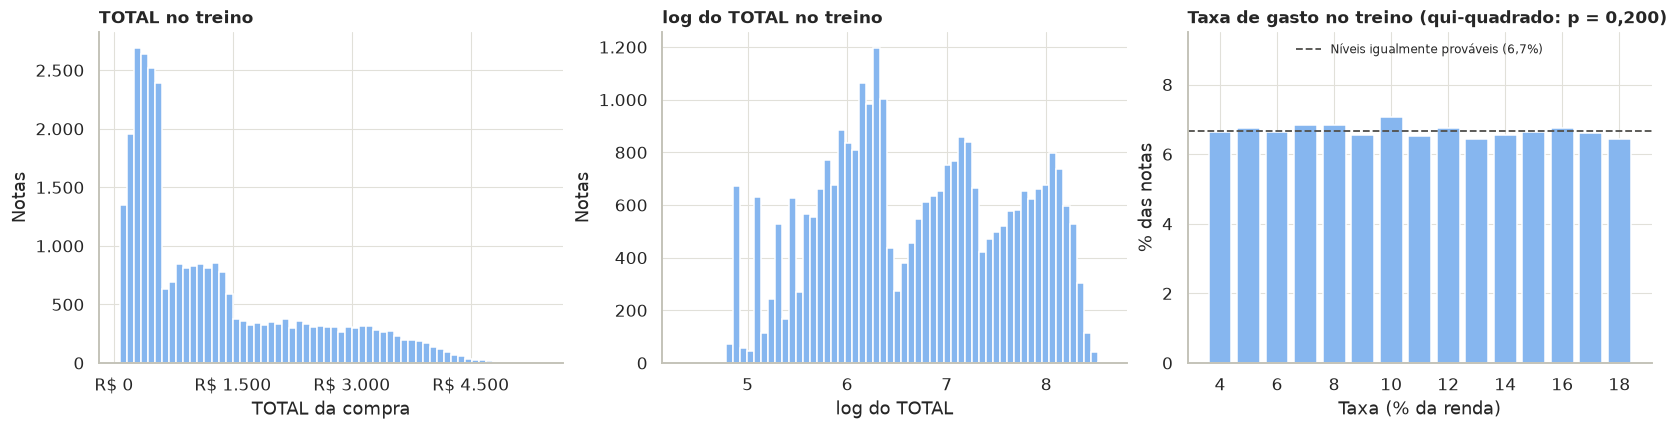

In [ ]:
regressao = AtividadeA1_1(conjuntos)

**Conclusão**

No treino, o log reduziu a assimetria do TOTAL de 1,127 para −0,004 e a da renda de 0,466 para 0,078. Na escala log, esperamos relação linear entre gasto e renda e ruído com a mesma amplitude em todas as faixas de renda; a A1.3 e a A1.4.3 conferem as duas coisas.

A taxa de gasto assumiu só os 15 níveis inteiros de 4% a 18% da renda, com frequências próximas: o qui-quadrado não rejeitou a hipótese de níveis igualmente prováveis (p = 0,200). Como na Parte 1, cada compra segue TOTAL = renda × taxa + R\$ 1,99. Se a taxa não depender de nenhuma outra variável, o que testamos na A1.2, o melhor que um modelo pode fazer é estimar a média do gasto para cada renda, calculada com essa distribuição da taxa. Chamamos de teto o R² dessa estimativa. Ele é calculado em cada conjunto, com a distribuição da taxa estimada no treino, e por isso o R² de um modelo pode passar dele por diferenças da ordem de 0,0001.

## Atividade A1.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [ ]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
etl_regressao = AtividadeA1_2(regressao, conjuntos)

**Quais variáveis podem entrar no regressor? (química: limiar de Bonferroni 0,0038)**

Variável,Momento,Teste no treino,Estatística,p-valor,Decisão
Plano,adesão,"Wald HC3 (2 gl), com renda e cadastro no modelo","1,735","0,420","candidata, comparada na A1.3"
"Região, sexo, estado civil e dependentes",adesão,"Wald HC3 (8 gl), com renda e plano no modelo","2,786","0,947","candidatas, comparadas na A1.3"
13 medidas químicas,compra,Spearman com a taxa (maior |ρ| das 13),"−0,014","0,018",fora: sem associação e com valores negativos
Nota de satisfação,depois da compra,Spearman com a taxa,"0,003","0,559",fora: medida depois da compra e sem associação
Opinião do cliente,depois da compra,qui-quadrado com a taxa,"346,902","0,329",fora: medida depois da compra e sem associação


&nbsp;

**Entradas (X) e saída (y) como ndarray**

,X: Renda,"X: Renda, plano e cadastro",y: log do TOTAL
Conjunto,,,
Treino,30.100 x 1,30.100 x 11,30.100
Validação,30.100 x 1,30.100 x 11,30.100
Teste,30.100 x 1,30.100 x 11,30.100
População,30.100 x 1,30.100 x 11,30.100


&nbsp;

**Conclusão**

Com a renda e o cadastro no modelo, não encontramos efeito do plano sobre o gasto (Wald com 2 graus de liberdade, p = 0,420). Com a renda e o plano, também não encontramos efeito do cadastro (8 graus de liberdade, p = 0,947). Os dois grupos seguem como candidatos e são comparados na A1.3.

As medidas químicas, a nota de satisfação e a opinião do cliente não se associaram à taxa de gasto. Na química, o maior |ρ| foi 0,014, com p = 0,018, acima do limiar de Bonferroni de 0,0038 para 13 testes. A nota e a opinião, além de não se associarem à taxa (p = 0,559 e p = 0,329), são medidas depois da compra e não estariam disponíveis para prever o gasto. Por isso, as três ficam fora do regressor.

Os quatro conjuntos seguem como ndarray com 30.100 linhas: uma coluna no grupo só com a renda e 11 no grupo com renda, plano e cadastro. A saída é o log do TOTAL.

## Atividade A1.3 (3º Passo): Criar o Modelo: **Regressors**

In [ ]:
regressor = AtividadeA1_3(etl_regressao)

**Regressores candidatos (R² na escala log)**

Modelo,Variáveis,Hiperparâmetros,R² treino,R² validação
Linear (renda),1,nenhum,"0,7769","0,7722"
"Linear (renda, plano e cadastro)",11,nenhum,"0,7769","0,7721"
Random forest,11,min_samples_leaf = 400,"0,7774","0,7700"
Gradient boosting,11,"learning_rate = 0,05, max_leaf_nodes = 7","0,7777","0,7715"


&nbsp;

**Bootstrap pareado contra o linear da renda (2.000 reamostras da validação, dentro dos planos)**

Modelo,Diferença de R² na validação,IC 95% inferior,IC 95% superior,p-valor (bootstrap),Supera o linear da renda?
"Linear (renda, plano e cadastro)","0,0000","−0,0001","0,0000","0,129",não
Random forest,"−0,0021","−0,0026","−0,0017","< 0,001",não
Gradient boosting,"−0,0007","−0,0009","−0,0004","< 0,001",não


&nbsp;

**Modelo escolhido: Linear (renda) (fator de Duan = 1,0944)**

,Coeficiente,IC 95% inferior (HC3),IC 95% superior (HC3)
Termo,,,
Intercepto,"−2,3122","−2,3670","−2,2574"
log da renda,"1,0016","0,9955","1,0076"


&nbsp;

**Conclusão**

O linear só com a renda teve R² de 0,7722 na validação. Acrescentar plano e cadastro não mudou o resultado (diferença de 0,0000, p = 0,129). A random forest e o gradient boosting tiveram, no treino, R² de 0,7774 e 0,7777, acima do teto do treino (0,7769, A1.4.1): parte do que ajustaram era ruído. Na validação, ficaram abaixo do linear, com diferenças de −0,0021 e −0,0007 (p < 0,001). Os melhores hiperparâmetros foram folhas com pelo menos 400 notas na random forest, o maior valor testado, e árvores com no máximo 7 folhas no gradient boosting, o menor; os dois aproximam esses modelos de uma função simples da renda. Como nenhum modelo passa do teto, ampliar a grade não mudaria a escolha.

Optamos pelo linear da renda. O coeficiente do log da renda foi 1,0016, com IC de 95% de 0,9955 a 1,0076 (erros HC3); o intervalo contém 1, o que é compatível com um gasto proporcional à renda. O fator de Duan, de 1,0944, corrige o viés da volta do log para reais. Com ele, o gasto estimado fica em torno de 11% da renda, a taxa média.

### A1.3.1: Intervalo de confiança: Train

**Treino: R² do modelo Linear (renda)**

Método,R² (log),Desvio-padrão,Menor parte,Maior parte,IC 95% inferior,IC 95% superior
Validação cruzada: média das 10 dobras,"0,7768","0,0049","0,7709","0,7844","0,7733","0,7803"
Bootstrap percentílico (2.000 reamostras dentro dos planos),"0,7769","0,0016",n/a,n/a,"0,7739","0,7799"


&nbsp;

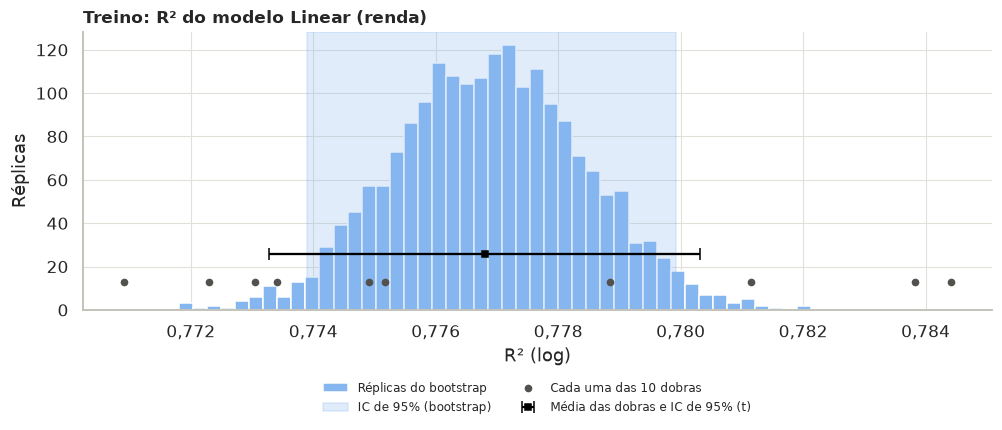

In [ ]:
# Validação Cruzada e Análise Bootstrapping
ic_treino_regressor = AtividadeA1_3_1(regressor, etl_regressao)

**Conclusão**

No treino, a validação cruzada com 10 dobras deu R² médio de 0,7768, com IC de 95% de 0,7733 a 0,7803; o R² das dobras foi de 0,7709 a 0,7844, com desvio-padrão de 0,0049. O bootstrap das previsões fora da dobra, feito dentro dos planos, deu 0,7769, com IC de 0,7739 a 0,7799. Os dois intervalos quase coincidem. Como as dobras compartilham o ajuste, o IC t é aproximado, e o bootstrap serve de conferência.

### A1.3.2: Intervalo de confiança: Validation

**Validação: R² do modelo Linear (renda)**

Método,R² (log),Desvio-padrão,Menor parte,Maior parte,IC 95% inferior,IC 95% superior
Partes da validação: média das 10 partes,"0,7720","0,0054","0,7647","0,7804","0,7681","0,7759"
Bootstrap percentílico (2.000 reamostras dentro dos planos),"0,7722","0,0016",n/a,n/a,"0,7691","0,7753"


&nbsp;

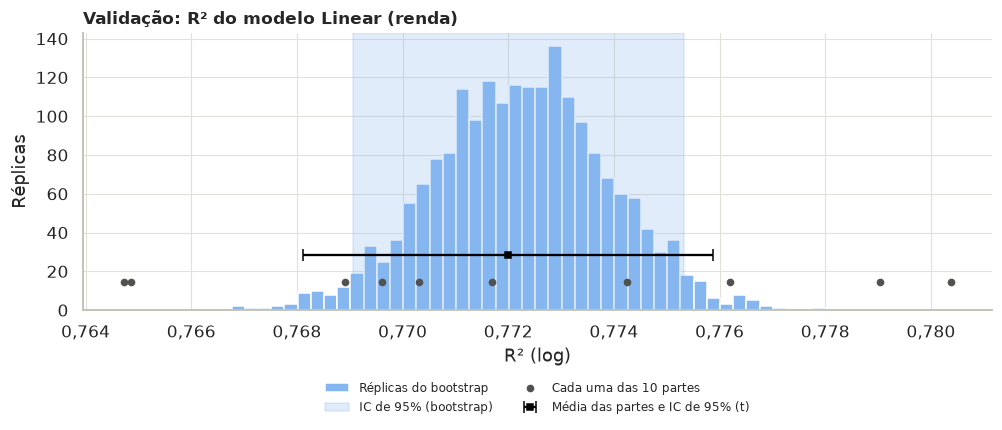

In [ ]:
# Validação Cruzada e Análise Bootstrapping
ic_validacao_regressor = AtividadeA1_3_2(regressor, etl_regressao)

**Conclusão**

Na validação, o R² foi 0,7722, com IC de 95% de 0,7691 a 0,7753 no bootstrap. A média das 10 partes deu 0,7720, com IC de 0,7681 a 0,7759, e o R² das partes foi de 0,7647 a 0,7804. O intervalo fica um pouco abaixo do intervalo do treino e se sobrepõe a ele. Como o R² da validação é igual ao teto desse conjunto (A1.4.1), a diferença vem da amostra, e não de perda de ajuste.

## Atividade A1.4 (4º Passo): Medir a acurácia (score) dos Modelos de Regressão:

### A1.4.1: Exibir os Coeficientes de Determinação ($R^2$)

* Conjunto de Treinamento: R² de 0,7769 na escala log e 0,6999 em reais, iguais ao teto.

* Conjunto de Validação: R² de 0,7722 na escala log e 0,6958 em reais, iguais ao teto.

* Conjunto de Teste: R² de 0,7728 na escala log e 0,6941 em reais (teto de 0,6942).

In [ ]:
# Train
r2_treino = AtividadeA1_4_1(regressor, etl_regressao, regressao, 'Treino')

**Treino: coeficiente de determinação (R²)**

Conjunto,R² (log),Teto do R² (log),R² (R$),Teto do R² (R$),RMSE (R$),MAE (R$),MAE (% do TOTAL médio)
Treino,"0,7769","0,7769","0,6999","0,6999","R$ 603,59","R$ 419,53","33,8"


&nbsp;

In [ ]:
# Validation
r2_validacao = AtividadeA1_4_1(regressor, etl_regressao, regressao, 'Validação')

**Validação: coeficiente de determinação (R²)**

Conjunto,R² (log),Teto do R² (log),R² (R$),Teto do R² (R$),RMSE (R$),MAE (R$),MAE (% do TOTAL médio)
Validação,"0,7722","0,7722","0,6958","0,6958","R$ 609,42","R$ 423,75","34,0"


&nbsp;

In [ ]:
# Teste
r2_teste = AtividadeA1_4_1(regressor, etl_regressao, regressao, 'Teste')

**Teste: coeficiente de determinação (R²)**

Conjunto,R² (log),Teto do R² (log),R² (R$),Teto do R² (R$),RMSE (R$),MAE (R$),MAE (% do TOTAL médio)
Teste,"0,7728","0,7728","0,6941","0,6942","R$ 605,59","R$ 420,33","34,0"


&nbsp;

**Conclusão**

Nos três conjuntos, o R² do modelo ficou no teto, com diferença máxima de 0,0001: 0,7769, 0,7722 e 0,7728 na escala log; 0,6999, 0,6958 e 0,6941 em reais.

O erro em reais continua grande: no teste, o MAE foi de R\$ 420, 34,0% do TOTAL médio, e o RMSE, de R\$ 606. Esse erro não vem do ajuste. Uma compra pode ter qualquer taxa entre 4% e 18% da renda, e nenhuma variável testada indica qual. O modelo estima bem o gasto médio de clientes com a mesma renda, mas não o valor exato de cada compra.

### A1.4.2: Plotagem dos Conjuntos - REAL ($y$) x ESTIMADO ($\hat{y}$):

* Conjunto de Treinamento: pontos em 15 faixas paralelas à reta real = estimado; R² de 0,700 em reais.

* Conjunto de Validação: as mesmas 15 faixas, sem afastamento da reta em nenhum plano; R² de 0,696 em reais.

* Conjunto de Teste: as mesmas faixas; R² de 0,694 em reais, sem perda em relação ao treino além da variação da amostra.

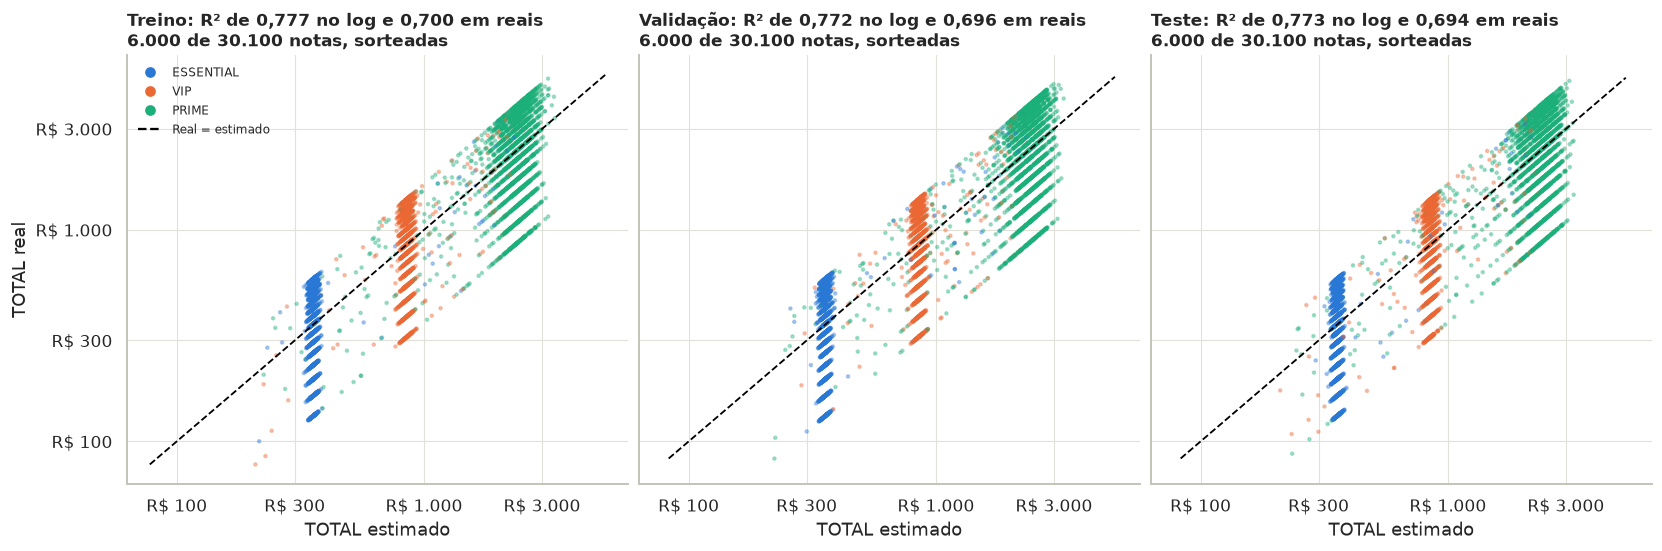

In [ ]:
AtividadeA1_4_2(regressor, etl_regressao)

**Conclusão**

Nos três conjuntos, os pontos acompanham a reta real = estimado em 15 faixas paralelas, uma por nível da taxa de gasto. No ESSENTIAL e no VIP, cuja renda ocupa faixas estreitas, o valor estimado varia pouco, e o valor real se espalha na vertical, conforme a taxa; no PRIME, a renda varia mais e as faixas se alongam. Os pontos fora das nuvens principais são compras de clientes com renda típica de outro plano, já identificadas na Parte 1. Cada painel mostra 6.000 notas sorteadas, e o R² do título usa todas as notas do conjunto.

### A1.4.3: Análise dos Resíduos: $\epsilon = y_{real} - y_{estimado}$

* Conjunto de Treinamento: média nula por construção; Breusch-Pagan p = 0,586; 15 níveis de resíduo.

* Conjunto de Validação: média de 0,0047 (p = 0,071); Breusch-Pagan p = 0,482.

* Conjunto de Teste: média de 0,0004 (p = 0,864); Breusch-Pagan p = 0,060, limítrofe.

**Testes dos resíduos (escala log)**

Conjunto,Média do resíduo,p-valor (média zero),A² (normalidade),Crítico 5%,Rejeita a normalidade?,p-valor Breusch-Pagan,p-valor por plano (KW)
Treino,"0,0000","1,000","618,0742","0,7520",sim,"0,586","< 0,001"
Validação,"0,0047","0,071","662,3995","0,7520",sim,"0,482","< 0,001"
Teste,"0,0004","0,864","635,5029","0,7520",sim,"0,060","< 0,001"


&nbsp;

**Resíduo médio por plano (escala log)**

,Treino,Validação,Teste
Plano,,,
ESSENTIAL,"−0,0019","0,0103","0,0083"
VIP,"0,0063","0,0046","−0,0011"
PRIME,"−0,0017","−0,0008","−0,0064"


&nbsp;

**Diferença das medianas dos resíduos entre planos, dentro do mesmo nível da taxa**

Conjunto,"ESSENTIAL menos PRIME, taxa de 4%","ESSENTIAL menos PRIME, taxa de 18%",p-valor KW da taxa por plano
Treino,"0,0158","0,0059","0,124"
Validação,"0,0159","0,0058","0,784"
Teste,"0,0158","0,0058","0,623"


&nbsp;

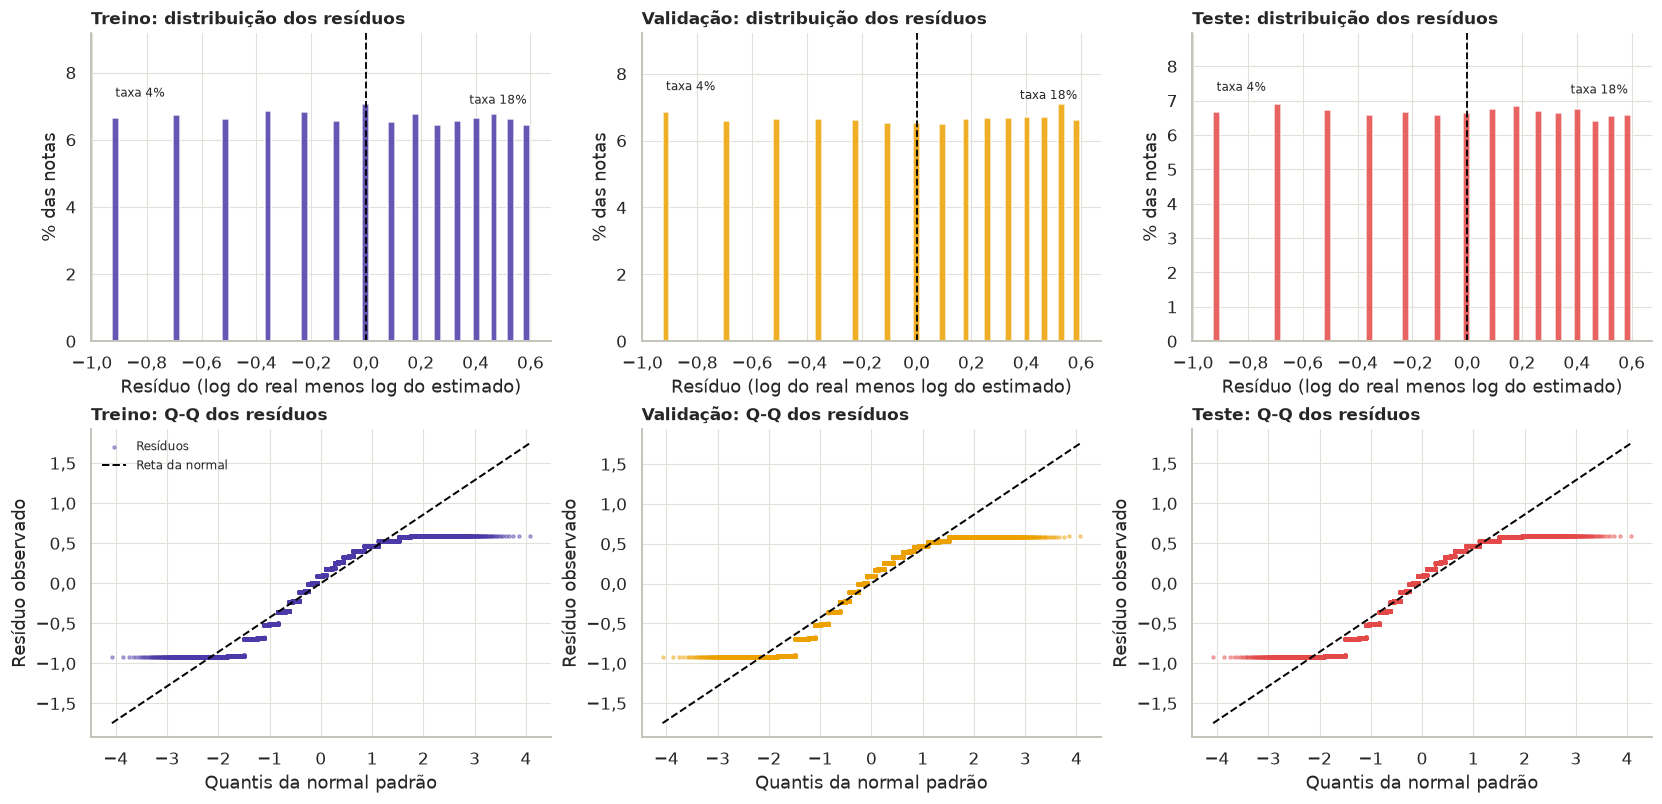

In [ ]:
residuos_regressor = AtividadeA1_4_3(regressor, etl_regressao)

**Conclusão**

No treino, a média dos resíduos é zero por construção, porque o modelo tem intercepto. Na validação e no teste, não rejeitamos a média zero (p = 0,071 e p = 0,864). O Breusch-Pagan, na versão de Koenker, que não supõe normalidade, não encontrou variância diferente ao longo do valor estimado (p de 0,060 a 0,586; no teste, o valor é limítrofe). A normalidade foi rejeitada nos três conjuntos (A² acima de 600, para um valor crítico de 0,752): os resíduos se concentram em 15 níveis, de −0,92 a 0,59, cada um com cerca de 6,7% das notas e correspondente a um nível da taxa de gasto. Os degraus do gráfico Q-Q mostram esses níveis. Os intervalos de confiança da A1.3 vêm do bootstrap e da validação cruzada, que não dependem da normalidade dos resíduos.

O Kruskal-Wallis detectou diferença dos resíduos entre os planos (p < 0,001). No mesmo nível da taxa, o resíduo do ESSENTIAL fica 1,6% acima do PRIME na taxa de 4% e 0,6% acima na de 18%. A diferença é compatível com a parcela fixa de R\$ 1,99, que pesa mais nas compras pequenas do ESSENTIAL, e com a inclinação estimada de 1,0016, um pouco acima de 1. A taxa em si não muda entre os planos (p de 0,124 a 0,784). As médias dos resíduos por plano ficaram entre −0,0064 e 0,0103, menos de 1,1% do gasto.

### A1.4.4: JOINT: Resíduos ($\epsilon$) vs Valores Estimado ($\hat{y}$)

* Conjunto de Treinamento: faixas horizontais de resíduos, sem formato de funil e sem curvatura.

* Conjunto de Validação: as mesmas faixas, com a mesma largura em todo o eixo do valor estimado.

* Conjunto de Teste: as mesmas faixas; nenhum plano se afasta do zero.

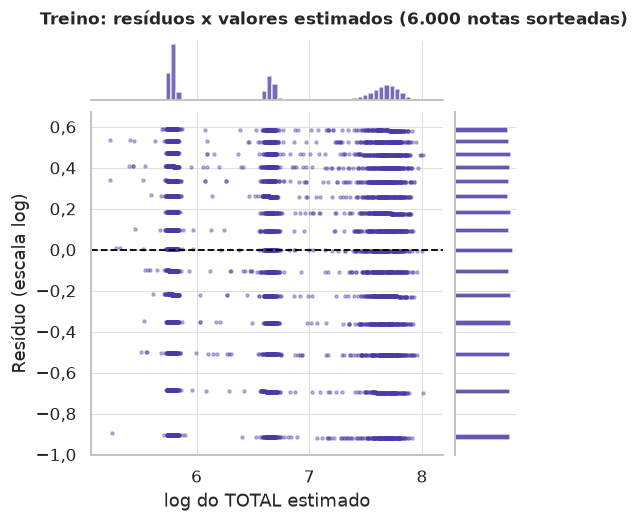

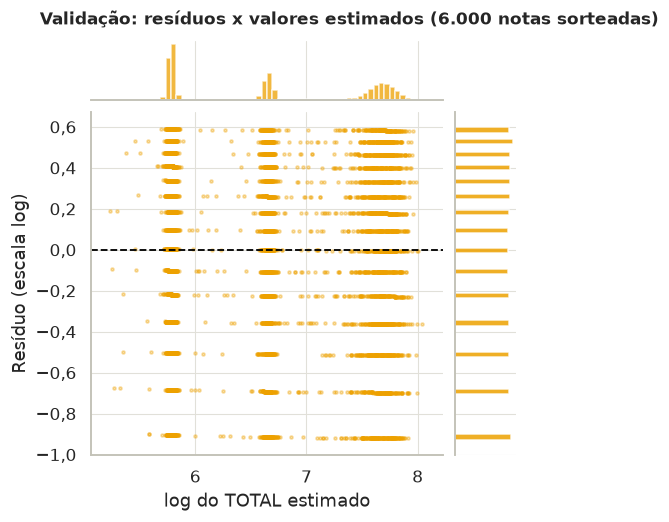

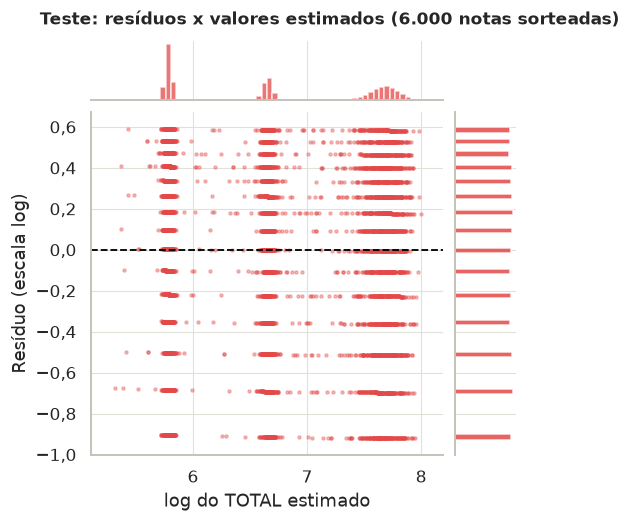

In [ ]:
AtividadeA1_4_4(regressor, etl_regressao)

**Conclusão**

Nos três conjuntos, os resíduos formam 15 faixas horizontais que não se abrem nem se fecham ao longo do valor estimado, o que é coerente com o Breusch-Pagan da A1.4.3. Na borda superior, os valores estimados se concentram em três grupos, um por plano; na borda lateral, os resíduos aparecem nos 15 níveis, com frequências parecidas. Também não há curvatura, e a relação linear na escala log se mantém adequada.

## Atividade A1.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

**Regressor no teste e na amostra da população**

Conjunto,R² (log),Teto do R² (log),R² (R$),Teto do R² (R$),RMSE (R$),MAE (R$),MAE (% do TOTAL médio),IC 95% do R² (log),CV da renda,Variância do log da renda
Teste,"0,7728","0,7728","0,6941","0,6942","R$ 605,59","R$ 420,33","34,0","0,7697 a 0,7761","0,739","0,685"
População,"0,7057","0,7057","0,7523","0,7522","R$ 408,83","R$ 260,07","33,7","0,7015 a 0,7098","0,920","0,477"


&nbsp;

Diferença de R² (log), população menos teste: −0,0672, IC de 95% de −0,0724 a −0,0621. Distribuição dos 15 níveis da taxa, teste x população: qui-quadrado 8,99, 14 graus de liberdade, p 0,832.

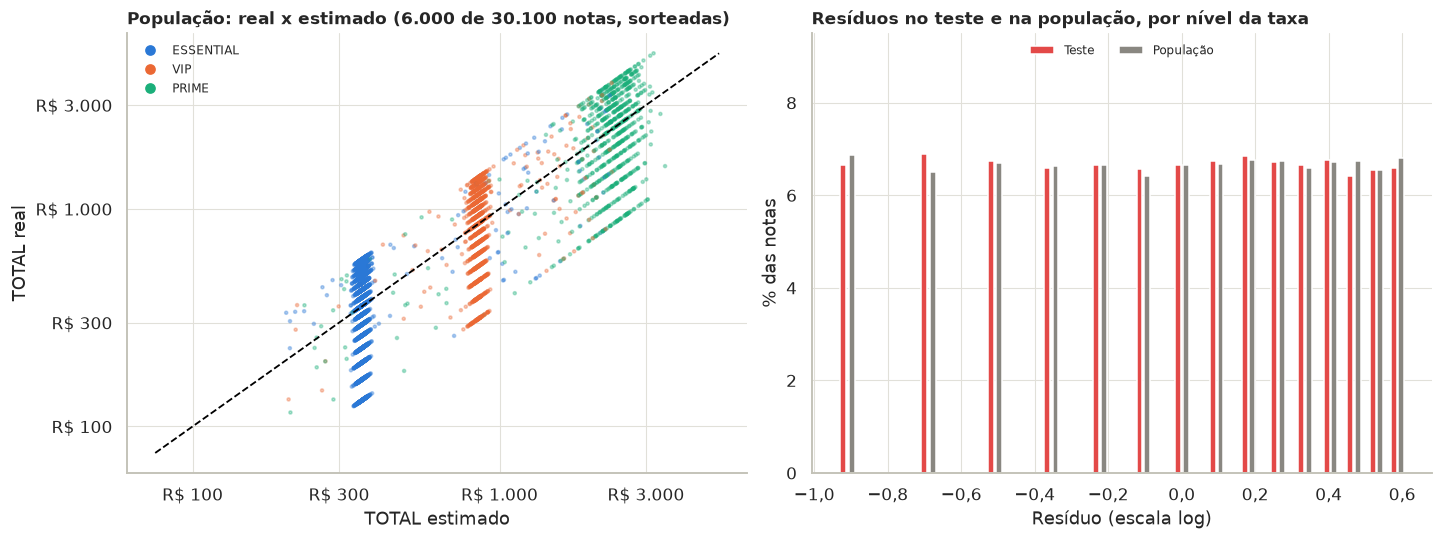

In [ ]:
populacao_regressor = AtividadeA1_5(regressor, etl_regressao, regressao)

**Conclusão**

Na amostra da população, o R² foi 0,7057 na escala log, com IC de 95% de 0,7015 a 0,7098, e 0,7523 em reais; os dois valores ficam no teto da população (0,7057 e 0,7522). Em relação ao teste, a diferença de R² na escala log foi de −0,0672 (IC de −0,0724 a −0,0621), e o R² em reais subiu. As duas mudanças vêm da composição da amostra, e não do modelo. Na escala log, o R² cresce com a variância do log da renda, menor na população (0,477) do que no teste (0,685), porque ela tem 14,9% de PRIME, contra 39,6%. Em reais, cresce com a dispersão relativa da renda, medida pelo coeficiente de variação, maior na população (0,920) do que no teste (0,739).

O MAE caiu para R\$ 260, 33,7% do TOTAL médio da população, quase a mesma proporção do teste (34,0%). A distribuição dos 15 níveis da taxa não difere entre teste e população (qui-quadrado p = 0,832).

## RELATÓRIO PARCIAL - MODELO DE REGRESSÃO

Fazer aqui o **RRELATÓRIO PARCIAL - MODELO DE REGRESSÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*   ✅ O gasto por compra é proporcional à renda do cliente: em média, 11% da renda, mais R\$ 1,99. O plano e os dados de cadastro (região, sexo, estado civil e dependentes) não melhoraram a previsão, e modelos mais complexos foram piores na validação.
*   ✅ O modelo chegou ao melhor resultado possível com os dados. No teste, ele explica 77% da variação do gasto medida em escala log, isto é, em diferenças percentuais, e 69% da variação em reais; na amostra da população, 71% e 75%. O que falta explicar é a taxa de gasto de cada compra, entre 4% e 18% da renda, que nenhuma variável testada indicou.
*   ✅ Para a gestão, o modelo serve para projetar o gasto médio de grupos de clientes a partir da renda, mas não o valor de uma compra isolada: o erro absoluto médio é de R\$ 260 por compra na população, cerca de um terço do gasto médio. Prever cada compra poderia exigir dados que a base não tem, como os itens comprados ou o histórico de cada cliente.

# Atividade A2: Modelo de Clusterização

## Atividade A2.1 (1º Passo): Normalizar - Mapear - Discretizar

**Normalizar, mapear e discretizar (padronização ajustada em treino e validação)**

Variável,Transformação,Motivo
Renda,log natural e padronização,assimetria; distância do K-means comparável entre variáveis
Dependentes,padronização,mesma escala das demais variáveis
"Região, sexo e estado civil",indicadoras padronizadas,variáveis qualitativas
13 medidas químicas,padronização,candidatas só para o teste de estrutura da A2.2
Faixa de renda,cortes entre os centros dos grupos (A2.5),só para descrever os grupos


&nbsp;

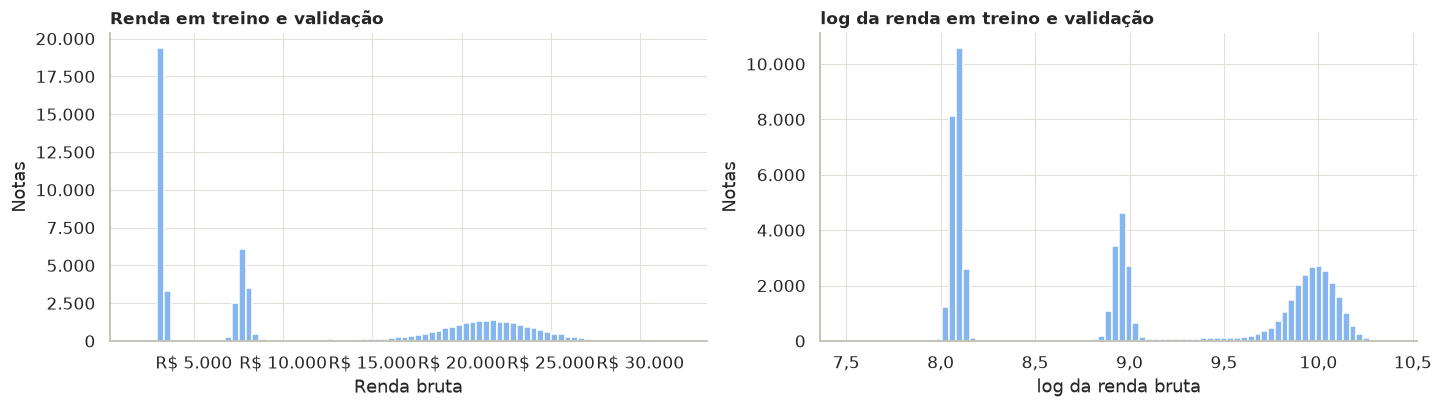

In [ ]:
agrupamento = AtividadeA2_1(conjuntos)

**Conclusão**

A renda tem distribuição assimétrica, com cauda longa no PRIME. Na escala log, ela forma três concentrações separadas por intervalos quase vazios, o que já sugere grupos naturais. A padronização deixa todas as candidatas com média 0 e desvio 1 em treino e validação, para que nenhuma domine a distância do K-means só pela escala.

## Atividade A2.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

**Variáveis que não entram no clusterizador**

Variável,Decisão,Motivo
TOTAL (R$),fora,"enunciado: é o gasto, alvo do regressor"
Plano,fora do ajuste,enunciado: fica só para avaliar os grupos
Nota de satisfação,fora,"repete o plano: varia em 0,00% do ESSENTIAL, 0,02% do VIP, 48,35% do PRIME (qui-quadrado p < 0,001)"
Opinião do cliente,fora,medida depois da compra


&nbsp;

**Silhueta do K-means por conjunto de variáveis, com k de 2 a 15 (K-means e silhueta numa amostra de 10.000 notas de treino e validação)**

,Maior silhueta,k da maior silhueta,Silhueta com k = 3
Variáveis,,,
Renda,"0,895",3,"0,895"
Renda e dependentes,"0,886",15,"0,530"
Renda e cadastro,"0,417",14,"0,364"
13 medidas químicas,"0,052",2,"0,047"


&nbsp;

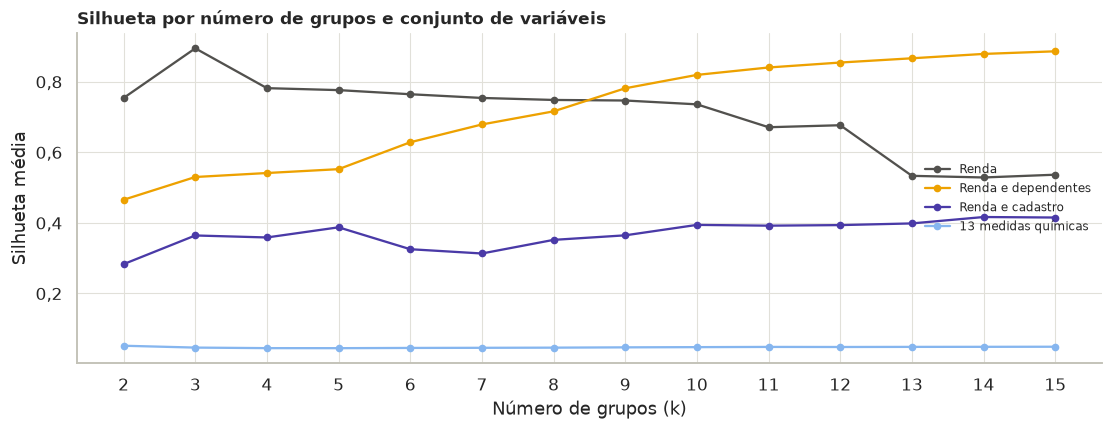

**Entrada (X) do clusterizador: renda**

,X,y
Conjunto,,
Treino,30.100 x 1,não há
Validação,30.100 x 1,não há
Teste,30.100 x 1,não há
População,30.100 x 1,não há


&nbsp;

In [ ]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
etl_agrupamento = AtividadeA2_2(agrupamento, conjuntos)

**Conclusão**

Gasto e plano ficam fora por definição do roteiro. A nota de satisfação também sai: ela varia em 48,3% das notas do PRIME, em nenhuma do ESSENTIAL e em 0,02% das do VIP (qui-quadrado p < 0,001), então funcionaria como um indicador do plano. A opinião do cliente é registrada depois da compra.

Com k de 2 a 15, na amostra de 10.000 notas, a renda sozinha teve a maior silhueta: 0,895, com três grupos. Somando os dependentes, a silhueta cresce com k até 0,886 em k = 15, porque os 5 valores possíveis de dependentes só subdividem cada faixa de renda; com três grupos, ela fica em 0,530. Somar todo o cadastro levou a no máximo 0,417, e as medidas químicas não formam grupos (silhueta máxima de 0,052). A entrada do clusterizador é, portanto, o log padronizado da renda.

## Atividade A2.3 (3º Passo): Aplicar o Método do Cotovelo

**Método do cotovelo (k indicado: 3)**

k,Inércia,Queda em relação ao k anterior (%),% da inércia de k = 1
1,"60.200,0",n/a,"100,0"
2,"10.364,5","82,8","17,2"
3,"913,6","91,2","1,5"
4,"530,1","42,0","0,9"
5,"366,6","30,8","0,6"
6,"289,1","21,2","0,5"
7,"230,9","20,1","0,4"
8,"192,4","16,7","0,3"
9,"158,1","17,8","0,3"
10,"135,8","14,1","0,2"


&nbsp;

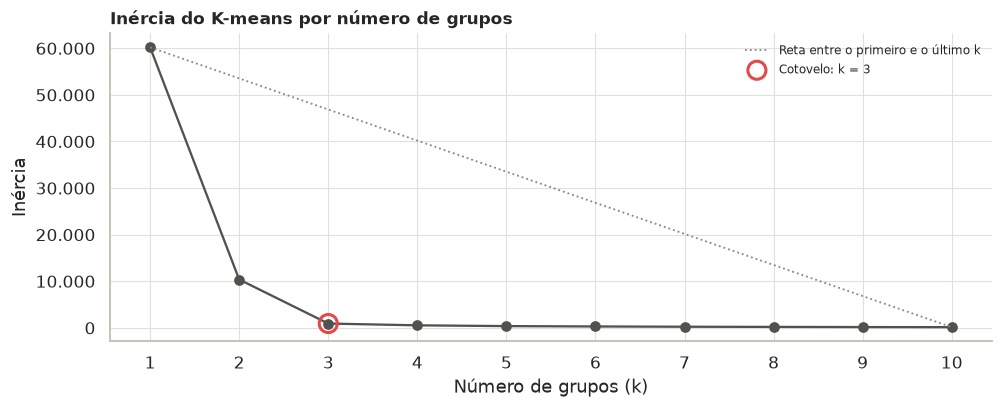

In [ ]:
cotovelo = AtividadeA2_3(etl_agrupamento)

**Conclusão**

A inércia caiu 82,8% de um para dois grupos e outros 91,2% de dois para três, sobre o valor de k = 2. Com três grupos, resta 1,5% da inércia de k = 1; a partir daí, cada grupo a mais reduz menos de 1% dessa inércia inicial. O ponto mais distante da reta entre o primeiro e o último k é k = 3.

## Atividade A2.4 (4º Passo): Aplicar o Método da Silhueta

**Método da silhueta (k indicado: 3)**

,k = 2,k = 3,k = 4,k = 5,k = 6,k = 7,k = 8,k = 9,k = 10
Silhueta média,"0,757","0,897","0,789","0,781","0,765","0,753","0,750","0,741","0,738"


&nbsp;

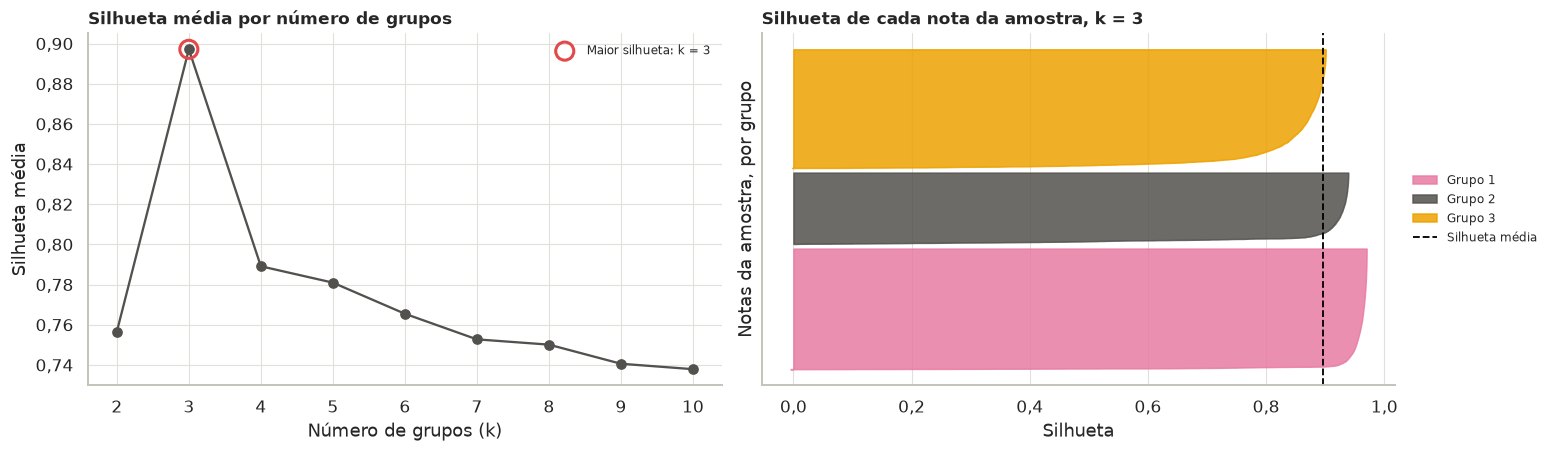

Com k = 3, a menor silhueta da amostra foi −0,005, e 2,0% das notas ficaram abaixo de 0,5.

In [ ]:
silhueta = AtividadeA2_4(etl_agrupamento)

**Conclusão**

A silhueta média foi máxima com três grupos (0,897), acima de k = 2 (0,757) e de k = 4 (0,789). O cotovelo e a silhueta indicam o mesmo número de grupos. No gráfico de cada nota, a silhueta fica perto de 1 na maior parte das notas: só 2,0% das notas da amostra ficaram abaixo de 0,5, e a menor silhueta foi −0,005, praticamente zero.

## Atividade A2.5 (5º Passo): Criar o Modelo: **Clusters**

In [ ]:
# NDARRAY - TRANINING: train e validation
clusterizador = AtividadeA2_5(etl_agrupamento, silhueta['k'])

**K-means com 3 grupos, ajustado em treino e validação**

Grupo,Notas no ajuste,"Centro (renda, R$)",Renda mínima (R$),Renda máxima (R$)
Grupo 1,23.217,"3.252,32","1.819,36","5.055,99"
Grupo 2,13.990,"7.863,93","5.057,41","12.923,74"
Grupo 3,22.993,"21.248,57","12.931,87","32.216,42"


&nbsp;

**Cortes de renda entre grupos vizinhos (ponto médio entre os centros, na escala log)**

Entre,Corte de renda (R$)
Grupo 1 e Grupo 2,"5.057,28"
Grupo 2 e Grupo 3,"12.926,61"


&nbsp;

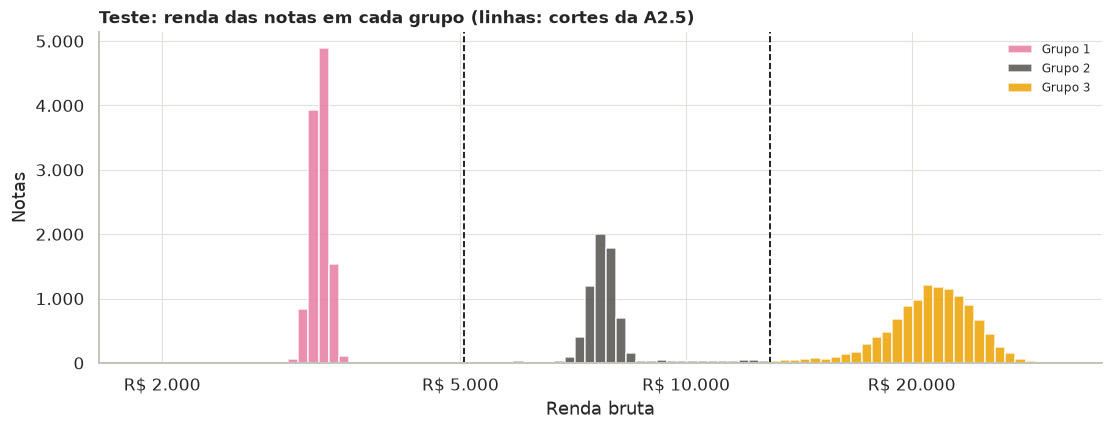

In [ ]:
# NDARRAY - TESTE: test
grupos_teste = AtividadeA2_5_teste(clusterizador, etl_agrupamento)

**Conclusão**

O K-means separou três faixas de renda, com centros em R\$ 3.252, R\$ 7.864 e R\$ 21.249, e cortes entre grupos vizinhos em R\$ 5.057 e R\$ 12.927. Na Parte 1, a árvore que reproduz os planos cortou em R\$ 3.587 e R\$ 11.732. As duas regras caem nos intervalos de renda com poucas notas e, por isso, classificam quase todas as notas do mesmo jeito. No teste, os três grupos aparecem nas mesmas faixas de renda do ajuste.

## Atividade A2.6 (6º Passo): Medir a acurácia (score) dos Modelos de Clusterização:

#### Atividade A2.6.1: Medir a Proporção dos clusters: Conjunto TRAIN

In [ ]:
grupos_treino = AtividadeA2_6(clusterizador, etl_agrupamento, 'Treino')

**Treino: proporção dos grupos e composição por plano**

,Notas,% do conjunto,ESSENTIAL (% do grupo),VIP (% do grupo),PRIME (% do grupo),Plano associado
Grupo,,,,,,
Grupo 1,11.612,"38,6","97,6","0,6","1,8",ESSENTIAL
Grupo 2,6.952,"23,1","1,5","91,8","6,7",VIP
Grupo 3,11.536,"38,3","0,9","1,7","97,4",PRIME


&nbsp;

**Treino: medidas do clusterizador**

Conjunto,Silhueta,Acurácia (grupo associado ao plano),Rand ajustado com os planos
Treino,"0,897","0,962","0,893"


&nbsp;

#### Atividade A2.6.2: Medir a Proporção dos clusters: Conjunto VALIDATION

In [ ]:
grupos_validacao = AtividadeA2_6(clusterizador, etl_agrupamento, 'Validação')

**Validação: proporção dos grupos e composição por plano**

,Notas,% do conjunto,ESSENTIAL (% do grupo),VIP (% do grupo),PRIME (% do grupo),Plano associado
Grupo,,,,,,
Grupo 1,11.605,"38,6","97,4","0,6","1,9",ESSENTIAL
Grupo 2,7.038,"23,4","1,7","90,7","7,6",VIP
Grupo 3,11.457,"38,1","1,0","1,7","97,3",PRIME


&nbsp;

**Validação: medidas do clusterizador**

Conjunto,Silhueta,Acurácia (grupo associado ao plano),Rand ajustado com os planos
Validação,"0,892","0,958","0,883"


&nbsp;

#### Atividade A2.6.3: Medir a Proporção dos clusters: Conjunto TEST

In [ ]:
medidas_teste = AtividadeA2_6(clusterizador, etl_agrupamento, 'Teste')
homogeneidade = comparar_grupos({'Treino': grupos_treino, 'Validação': grupos_validacao, 'Teste': medidas_teste})

**Teste: proporção dos grupos e composição por plano**

,Notas,% do conjunto,ESSENTIAL (% do grupo),VIP (% do grupo),PRIME (% do grupo),Plano associado
Grupo,,,,,,
Grupo 1,11.596,"38,5","97,7","0,8","1,5",ESSENTIAL
Grupo 2,6.954,"23,1","1,5","91,3","7,2",VIP
Grupo 3,11.550,"38,4","0,9","1,8","97,2",PRIME


&nbsp;

**Teste: medidas do clusterizador**

Conjunto,Silhueta,Acurácia (grupo associado ao plano),Rand ajustado com os planos
Teste,"0,895","0,960","0,890"


&nbsp;

**Proporção dos grupos (%) nos três conjuntos: qui-quadrado 1,14, 4 graus de liberdade, p 0,888**

,Treino,Validação,Teste
Grupo,,,
Grupo 1,"38,6","38,6","38,5"
Grupo 2,"23,1","23,4","23,1"
Grupo 3,"38,3","38,1","38,4"


&nbsp;

**Conclusão**

Os grupos têm proporções quase iguais nos três conjuntos: de 38,5% a 38,6% no Grupo 1, de 23,1% a 23,4% no Grupo 2 e de 38,1% a 38,4% no Grupo 3 (qui-quadrado p = 0,888). A silhueta ficou entre 0,892 e 0,897.

Sem usar o plano no ajuste, cada grupo corresponde a um plano. O Grupo 1 tem de 97,4% a 97,7% de ESSENTIAL, o Grupo 3 tem de 97,2% a 97,4% de PRIME, e o Grupo 2, de 90,7% a 91,8% de VIP. Associando cada grupo ao seu plano mais frequente, a acurácia foi de 95,8% a 96,2%, e o Rand ajustado ficou entre 0,883 e 0,893. O Grupo 2 é o menos puro, porque recebe de 6,7% a 7,6% de PRIME: clientes desse plano com renda típica de VIP. O plano associado a cada grupo vem do ajuste e é o mesmo nos cinco conjuntos. Como a validação fez parte do ajuste do K-means, só o teste e a população são avaliações fora da amostra; e, como as amostras têm o número de notas de cada plano fixo, os p-valores do qui-quadrado são conservadores.

## Atividade A2.7 (7º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

**População: proporção dos grupos e composição por plano**

,Notas,% do conjunto,ESSENTIAL (% do grupo),VIP (% do grupo),PRIME (% do grupo),Plano associado
Grupo,,,,,,
Grupo 1,19.063,"63,3","99,2","0,4","0,4",ESSENTIAL
Grupo 2,6.468,"21,5","2,8","94,4","2,9",VIP
Grupo 3,4.569,"15,2","3,7","3,9","92,4",PRIME


&nbsp;

**População: medidas do clusterizador**

Conjunto,Silhueta,Acurácia (grupo associado ao plano),Rand ajustado com os planos
População,"0,928","0,971","0,930"


&nbsp;

**Proporção dos grupos: amostra da população x base completa (qui-quadrado de aderência: p 0,870)**

,Amostra da população (%),Base completa (%)
Grupo,,
Grupo 1,"63,3","63,2"
Grupo 2,"21,5","21,5"
Grupo 3,"15,2","15,3"


&nbsp;

Na base completa, a acurácia da associação grupo e plano é 97,0% e o Rand ajustado, 0,927.

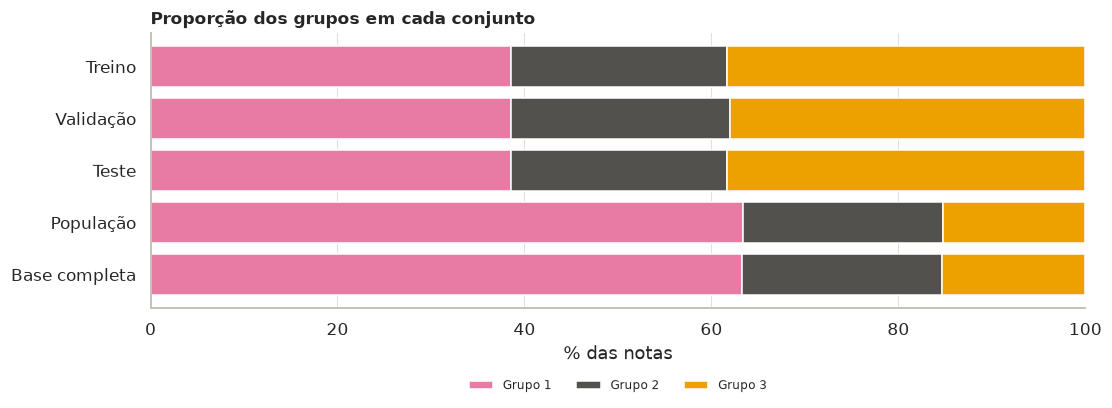

In [ ]:
populacao_clusterizador = AtividadeA2_7(clusterizador, etl_agrupamento, base)

**Conclusão**

Na amostra da população, os grupos ficaram com 63,3%, 21,5% e 15,2% das notas, perto das proporções da base completa (63,2%, 21,5% e 15,3%; qui-quadrado de aderência p = 0,870). A diferença em relação a treino, validação e teste vem do desenho de Neyman, que aumenta a participação do PRIME, e não do modelo.

Na população, a silhueta foi 0,928, e a acurácia da associação entre grupo e plano, 97,1%, com Rand ajustado de 0,930. Na base completa, esses valores foram 97,0% e 0,927. O Grupo 3 é o menos puro na população (92,4% de PRIME): nela, ESSENTIAL e VIP são mais numerosos, e uma pequena parte desses clientes tem renda de PRIME.

## RELATÓRIO PARCIAL - MODELO DE CLUSTERIZAÇÃO

Fazer aqui o **RELATÓRIO PARCIAL - MODELO DE CLUSTERIZAÇÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*   ✅ Sem usar o plano nem o gasto, o modelo de agrupamento (K-means) separou os clientes em três segmentos de renda: até R\$ 5.057, de R\$ 5.057 a R\$ 12.927 e acima de R\$ 12.927. A separação é forte: a silhueta, que vai de 0 a 1, ficou em 0,897. Somar o cadastro à renda não melhorou a separação, e as medidas químicas sozinhas não formaram grupos.
*   ✅ Os segmentos coincidem com os planos em 97,0% das notas da base: o Grupo 1 corresponde ao ESSENTIAL, o Grupo 2 ao VIP e o Grupo 3 ao PRIME. A política de planos por faixa de renda aparece nos dados mesmo sem informar o plano ao modelo.
*   ✅ As notas fora do segmento do próprio plano, 3,0% da base, são de clientes com renda típica de outro plano. Para a gestão, esses clientes são os candidatos naturais a uma revisão de plano, que a Parte 1 já tinha identificado pela renda.

# Atividade A3: Modelo de Classificação

## Atividade A3.1 (1º Passo): Normalizar - Mapear - Discretizar

**Normalizar, mapear e discretizar**

Variável,Transformação,Motivo
Plano (saída),"código 0, 1 e 2 (ESSENTIAL, VIP e PRIME)",formato usado pelos classificadores
Renda,log natural; padronização dentro de cada modelo,"assimetria; escala comum para SVM, vizinhos e rede neural"
"Região, sexo e estado civil",indicadoras (referência: primeira categoria),variáveis qualitativas
Dependentes,mantida como número (0 a 4),variável discreta e ordenada
Nota de satisfação,"discretizada em fixa (68,68) ou variável",só para o teste de vazamento da A3.2
TOTAL (R$),log natural,só para o teste de vazamento da A3.2


&nbsp;

**Planos em cada conjunto**

,ESSENTIAL,VIP,PRIME,ESSENTIAL (%),VIP (%),PRIME (%)
Conjunto,,,,,,
Treino,11.542,6.650,11.908,"38,3","22,1","39,6"
Validação,11.542,6.650,11.908,"38,3","22,1","39,6"
Teste,11.542,6.650,11.908,"38,3","22,1","39,6"
População,19.260,6.357,4.483,"64,0","21,1","14,9"


&nbsp;

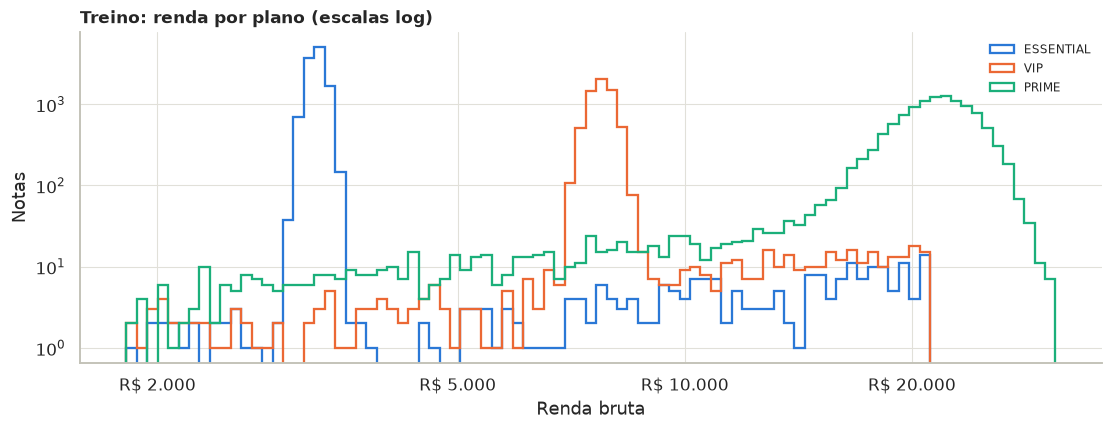

In [ ]:
classificacao = AtividadeA3_1(conjuntos)

**Conclusão**

O plano virou o código 0, 1 e 2, e a renda entra em log, com a padronização ajustada dentro de cada modelo. Nos três conjuntos de Neyman, o PRIME tem 39,6% das notas; na amostra da população, 14,9%.

No treino, cada plano ocupa uma faixa estreita de renda: o ESSENTIAL se concentra perto de R\$ 3.200, o VIP perto de R\$ 8.000 e o PRIME entre R\$ 13.000 e R\$ 30.000. Entre essas faixas aparecem poucas notas, principalmente do PRIME, mas também do ESSENTIAL e do VIP. Os clientes ESSENTIAL e VIP com renda fora da faixa do próprio plano formam o erro que um modelo baseado só na renda não consegue evitar.

## Atividade A3.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [ ]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
etl_classificacao = AtividadeA3_2(classificacao, conjuntos)

**Testes de vazamento e de ganho de informação para o classificador**

Hipótese nula,Teste,Estatística,p-valor,Leitura
O gasto tem a mesma distribuição nos três planos,Kruskal-Wallis (treino),"21.408,03","< 0,001",associação sem controlar a renda
"Dada a renda, o plano não altera o gasto",Wald HC3 (treino),"1,70","0,427",log TOTAL ~ log renda + plano
A taxa de gasto independe do plano,qui-quadrado 15 x 3 (treino),"21,67","0,796","taxa = (TOTAL menos R$ 1,99) / renda"
Incluir o gasto não muda os acertos,McNemar (validação),"5,45","0,020","32 acertos só sem o gasto e 15 só com o gasto; acurácia 97,09% sem e 97,03% com"
A nota variável aparece na mesma proporção nos três planos,qui-quadrado (treino),"10.928,80","< 0,001","nota variável em 0,00% do ESSENTIAL, 0,00% do VIP, 48,54% do PRIME"
Incluir a nota não muda os acertos,McNemar (validação),"0,00","1,000","0 acertos só sem a nota e 1 só com a nota; acurácia 97,09% sem e 97,09% com"
As medidas químicas têm a mesma distribuição nos três planos,"Kruskal-Wallis, 13 testes (treino)",n/a,"0,092","menor p-valor dos 13; limiar de Bonferroni 0,0038"
Incluir o cadastro não muda os acertos,McNemar (validação),"6,57","0,010","31 acertos só sem o cadastro e 13 só com o cadastro; acurácia 97,09% sem e 97,03% com"


&nbsp;

**Decisão sobre as variáveis do classificador**

Variável,Momento,Decisão,Motivo
Renda,adesão,entra,"principal variável associada ao plano (Parte 1, Extra 1)"
Cadastro,adesão,fora,não melhora os acertos (McNemar)
Gasto (TOTAL),compra,fora,não informa o plano além da renda e só existe depois da compra
Nota de satisfação,depois da compra,fora,gerada a partir do plano: vazamento do alvo
13 medidas químicas,compra,fora,sem associação com o plano
Opinião do cliente,depois da compra,fora,medida depois da compra


&nbsp;

**Entrada (X) e saída (y) do classificador como ndarray**

,X,"y: plano (0, 1, 2)"
Conjunto,,
Treino,30.100 x 1,30.100
Validação,30.100 x 1,30.100
Teste,30.100 x 1,30.100
População,30.100 x 1,30.100


&nbsp;

**Conclusão**

Sem controlar a renda, o gasto difere muito entre os planos (Kruskal-Wallis H = 21.408, p < 0,001). Com a renda no modelo, porém, não encontramos efeito do plano sobre o gasto (Wald p = 0,427), e a taxa de gasto não difere entre os planos (p = 0,796). Os resultados são compatíveis com uma associação entre gasto e plano que passa toda pela renda: não há sinal de que o gasto tenha sido gerado a partir do plano, o que caracterizaria vazamento do alvo. O gasto também não acrescentou informação. Com ele, o modelo passou a acertar 15 notas que errava e a errar 32 que acertava, e a acurácia foi de 97,09% para 97,03% (McNemar p = 0,020). Como o gasto só existe depois da compra e o plano é escolhido na adesão, ele fica fora.

A nota de satisfação varia em 48,5% das notas do PRIME no treino e quase nunca nos outros planos (qui-quadrado p < 0,001), o que indica que ela foi gerada a partir do próprio plano; além disso, é medida depois da compra. Nesta base, ela não mudou os acertos (p = 1,000), porque a renda já identifica quase todo o PRIME. Mesmo assim, fica fora. As medidas químicas não diferem entre os planos (menor p = 0,092, acima do limiar de Bonferroni de 0,0038), e o cadastro não melhorou os acertos: com ele, houve mais erros novos do que acertos novos (31 contra 13). A entrada do classificador é só o log da renda.

## Atividade A3.3 (3º Passo): Escolher / Criar o Modelo: **Classifiers**

Escolher enter os seguintes - **Classifiers**:

1.   Nearest Neighbors
2.   Linear SVM
2.   RBF SVM
2.   Gaussian Process
2.   Decision Tree
2.   Random Forest
2.   Neural Net
2.   AdaBoost
2.   Naive Bayes
2.   QDA

**Qual obteve o maior SCORE ?**

**Os 10 classificadores: score (acurácia) no treino e na validação (teto estimado só com a renda: 0,9720)**

Classificador,Notas no ajuste,Score no treino,Score na validação,Acurácia balanceada (validação),F1 macro (validação),p-valor contra o melhor (Holm),Diferente do melhor?
Decision Tree,30.100,"0,9737","0,9711","0,9661","0,9690",n/a,n/a
Random Forest,30.100,"0,9738","0,9711","0,9663","0,9689","1,000",não
RBF SVM,30.100,"0,9687","0,9677","0,9647","0,9651","< 0,001",sim
Nearest Neighbors,30.100,"0,9766","0,9654","0,9619","0,9629","< 0,001",sim
AdaBoost,30.100,"0,9676","0,9646","0,9629","0,9615","< 0,001",sim
Gaussian Process,1.000,"0,9666","0,9640","0,9627","0,9609","< 0,001",sim
QDA,30.100,"0,9638","0,9610","0,9597","0,9583","< 0,001",sim
Naive Bayes,30.100,"0,9638","0,9610","0,9597","0,9583","< 0,001",sim
Linear SVM,30.100,"0,9631","0,9602","0,9597","0,9571","< 0,001",sim
Neural Net,30.100,"0,9632","0,9600","0,9594","0,9570","< 0,001",sim


&nbsp;

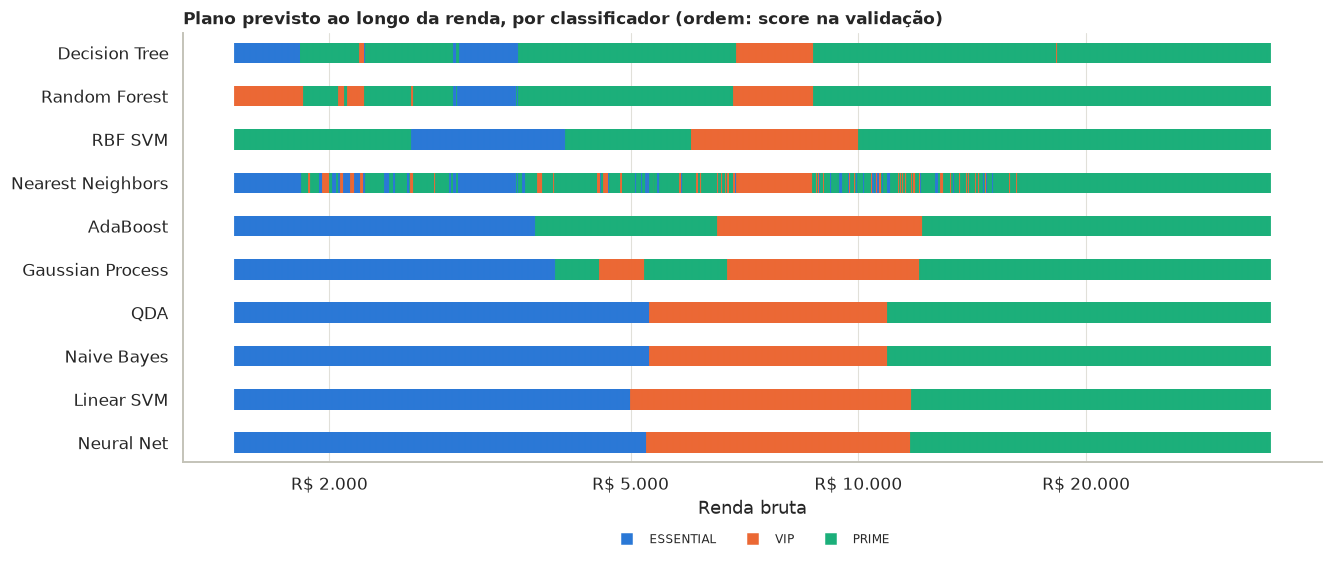

In [ ]:
classificador = AtividadeA3_3(etl_classificacao, base)

**Conclusão**

O Decision Tree obteve o maior score na validação: 0,9711, empatado com o Random Forest (0,9711; McNemar p = 1,000). Os outros oito ficaram entre 0,9600 e 0,9677, todos abaixo do Decision Tree com diferença significativa (p < 0,001 após a correção de Holm). Escolhemos o Decision Tree, que tem o mesmo score e é mais simples.

O gráfico mostra a origem da diferença. Os modelos de fronteira suave (QDA, Naive Bayes, Linear SVM e Neural Net) dividem a renda em três faixas contínuas. As árvores, além das três faixas, marcam como PRIME os intervalos de renda entre os planos, onde aparecem principalmente clientes do PRIME com renda atípica. O ganho é de cerca de um ponto percentual, porque poucas notas caem nesses intervalos. O Gaussian Process, ajustado em 1.000 notas, ficou com 0,9640. A estimativa do teto só com a renda, na composição da validação, é 0,9720: o Decision Tree fica a 0,0009 dela.

### A3.3.1: Intervalo de confiança: Train

**Treino: score do Decision Tree**

Método,Score (acurácia),Desvio-padrão,Menor parte,Maior parte,IC 95% inferior,IC 95% superior
Validação cruzada: média das 10 dobras,"0,9725","0,0037","0,9674","0,9771","0,9699","0,9751"
Bootstrap percentílico (2.000 reamostras dentro dos planos),"0,9725","0,0009",n/a,n/a,"0,9707","0,9743"


&nbsp;

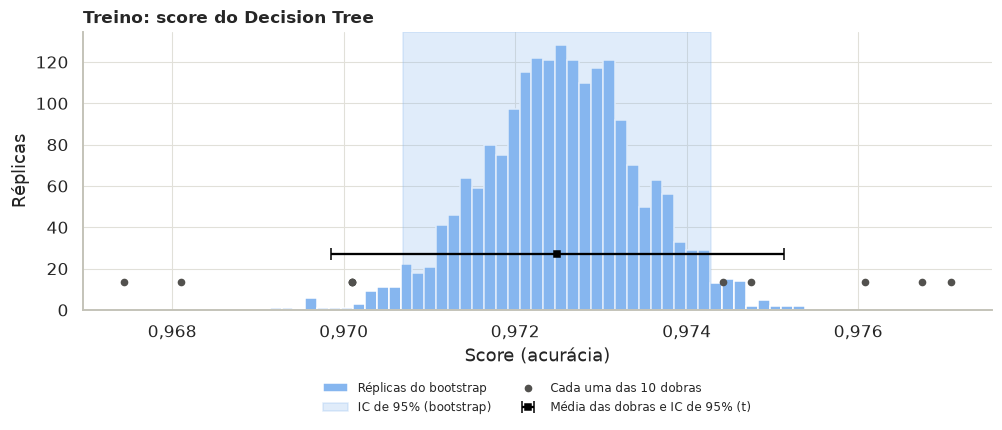

In [ ]:
ic_treino_classificador = AtividadeA3_3_1(classificador, etl_classificacao)

**Conclusão**

No treino, a validação cruzada estratificada com 10 dobras deu score médio de 0,9725, com IC de 95% de 0,9699 a 0,9751; o score das dobras foi de 0,9674 a 0,9771 (desvio-padrão de 0,0037). O bootstrap dos acertos fora da dobra, feito dentro dos planos, deu 0,9725, com IC de 0,9707 a 0,9743. O score no treino completo foi 0,9737, pouco acima da validação cruzada, o que indica um ajuste pequeno ao próprio treino.

### A3.3.2: Intervalo de confiança: Validation

**Validação: score do Decision Tree**

Método,Score (acurácia),Desvio-padrão,Menor parte,Maior parte,IC 95% inferior,IC 95% superior
Partes da validação: média das 10 partes,"0,9711","0,0034","0,9651","0,9767","0,9686","0,9735"
Bootstrap percentílico (2.000 reamostras dentro dos planos),"0,9711","0,0010",n/a,n/a,"0,9693","0,9730"


&nbsp;

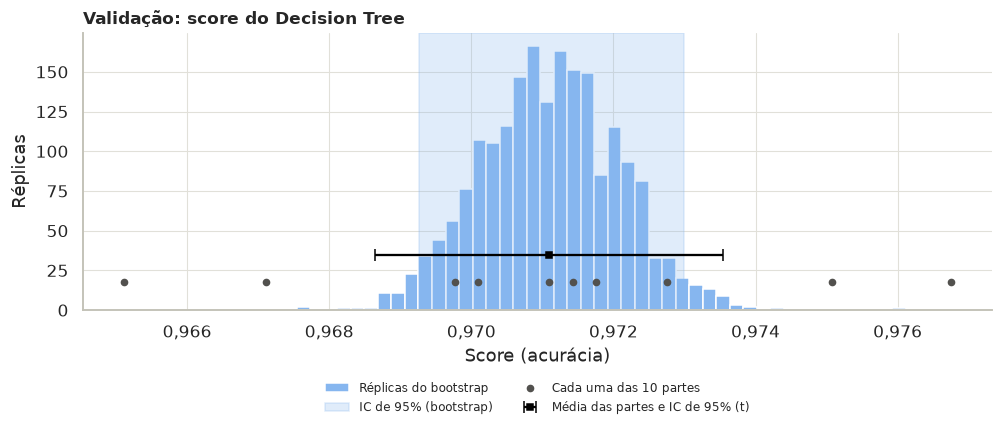

In [ ]:
ic_validacao_classificador = AtividadeA3_3_2(classificador, etl_classificacao)

**Conclusão**

Na validação, o score foi 0,9711, com IC de 95% de 0,9693 a 0,9730 no bootstrap; a média das 10 partes deu o mesmo valor, com IC de 0,9686 a 0,9735 e scores de 0,9651 a 0,9767. O intervalo se sobrepõe ao do treino, e a diferença entre os dois scores (0,0014) fica dentro da variação esperada para amostras desse tamanho.

## Atividade A3.4 (4º Passo): Medir a acurácia (score) dos Modelos de Classificação:

#### Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TRAIN

**Treino: medidas por plano (score = acurácia: 0,9737)**

,Notas,Precisão,Recall,F1
Plano,,,,
ESSENTIAL,11.542,"0,9960","0,9796","0,9877"
VIP,6.650,"0,9773","0,9392","0,9579"
PRIME,11.908,"0,9513","0,9872","0,9689"


&nbsp;

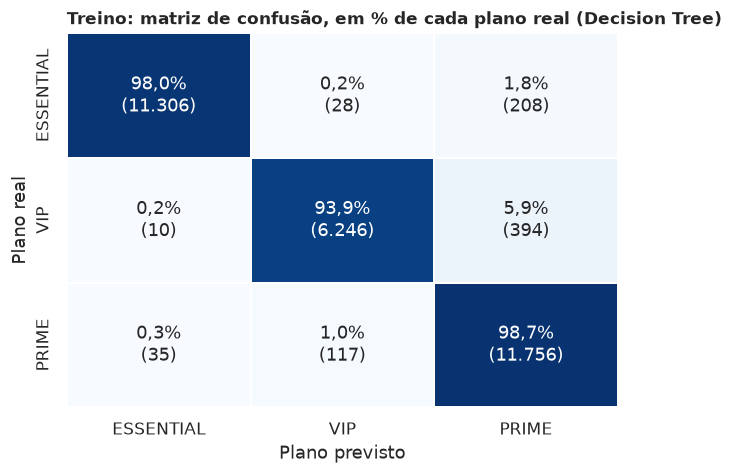

In [ ]:
matriz_treino = AtividadeA3_4(classificador, etl_classificacao, 'Treino')

#### Atividade A3.4.2: Medir a acurácia (score) - Matriz de Confusão: Conjunto VALIDATION

**Validação: medidas por plano (score = acurácia: 0,9711)**

,Notas,Precisão,Recall,F1
Plano,,,,
ESSENTIAL,11.542,"0,9947","0,9756","0,9850"
VIP,6.650,"0,9753","0,9371","0,9558"
PRIME,11.908,"0,9474","0,9857","0,9662"


&nbsp;

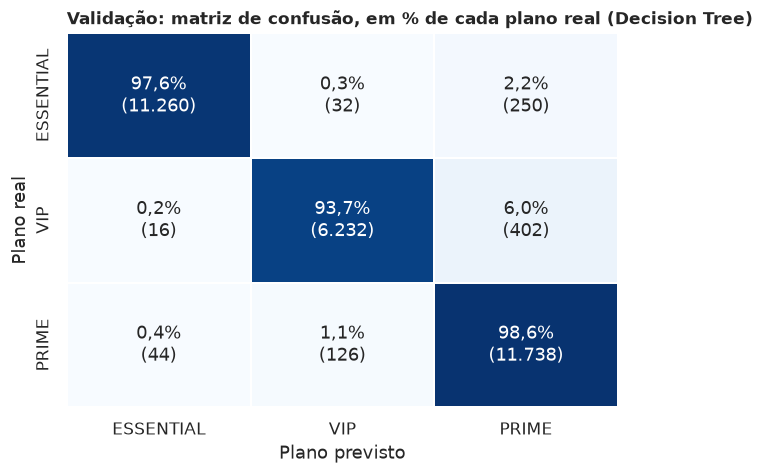

In [ ]:
matriz_validacao = AtividadeA3_4(classificador, etl_classificacao, 'Validação')

#### Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TEST

**Teste: medidas por plano (score = acurácia: 0,9709)**

,Notas,Precisão,Recall,F1
Plano,,,,
ESSENTIAL,11.542,"0,9954","0,9783","0,9868"
VIP,6.650,"0,9739","0,9311","0,9520"
PRIME,11.908,"0,9469","0,9859","0,9660"


&nbsp;

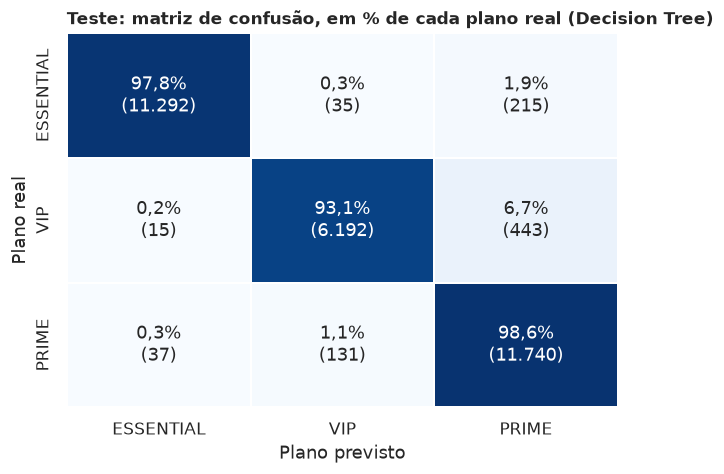

In [ ]:
matriz_teste = AtividadeA3_4(classificador, etl_classificacao, 'Teste')

**Conclusão**

A acurácia ficou em 0,9737 no treino, 0,9711 na validação e 0,9709 no teste. O ESSENTIAL tem a maior precisão (0,995 no teste) e o PRIME, o maior recall (0,986). O VIP tem o menor recall (0,931 no teste), e quase todos os seus erros são previstos como PRIME (443 de 458 no teste), porque o modelo atribui ao PRIME os intervalos de renda vizinhos ao VIP. O padrão se repete nos três conjuntos, com recall do VIP entre 0,931 e 0,939.

## Atividade A3.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

**Classificador no teste e na amostra da população**

Conjunto,Previsão,Score (acurácia),IC 95% do score,Acurácia balanceada,F1 macro,Previstos ESSENTIAL (%),Previstos VIP (%),Previstos PRIME (%)
Teste,sem correção,"0,9709","0,9689 a 0,9727","0,9651","0,9683","37,7","21,1","41,2"
População,sem correção,"0,9708","0,9688 a 0,9726","0,9678","0,9547","62,6","20,1","17,3"
População,com correção a priori,"0,9716","0,9697 a 0,9734","0,9629","0,9572","63,3","21,0","15,7"


&nbsp;

Planos reais na amostra da população: ESSENTIAL 64,0%, VIP 21,1%, PRIME 14,9%. Com a correção, o modelo passou a acertar 182 notas e a errar 156 que acertava (McNemar p 0,174). Teto estimado só com a renda, na composição da base: 0,9707.

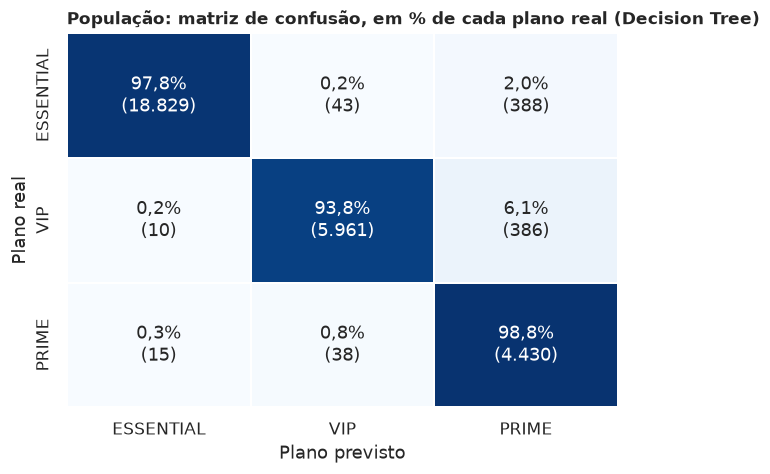

In [ ]:
populacao_classificador = AtividadeA3_5(classificador, etl_classificacao, base)

**Conclusão**

Na amostra da população, o score foi 0,9708, com IC de 95% de 0,9688 a 0,9726, praticamente igual ao do teste (0,9709). A composição dos planos muda, mas a regra de renda continua válida. Como o modelo foi treinado com 39,6% de PRIME, ele previu 17,3% de PRIME na população, onde a proporção real é 14,9%.

Com as probabilidades corrigidas para os pesos dos planos na base, a previsão de PRIME caiu para 15,7%, e o score foi para 0,9716 (IC de 0,9697 a 0,9734). A diferença é pequena: o modelo passou a acertar 182 notas que errava e a errar 156 que acertava (McNemar p = 0,174), e a acurácia balanceada caiu de 0,968 para 0,963, porque o modelo passa a errar mais o PRIME. A estimativa do teto só com a renda, na composição da base, é 0,9707, e os dois scores da população ficam dentro da variação amostral em torno dela. Na população, a maior parte dos erros é de ESSENTIAL e VIP previstos como PRIME (388 e 386 notas).

## RELATÓRIO PARCIAL - MODELO DE CLASSIFICAÇÃO

Fazer aqui o **RELATÓRIO PARCIAL - MODELO DE CLASSIFICAÇÃO** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*   ✅ O plano do cliente pode ser previsto na adesão só com a renda: o modelo escolhido, uma árvore de decisão, acertou 97 de cada 100 notas no teste e na amostra da população, praticamente o máximo possível só com a renda (97,1% na população). Entre os 10 modelos testados, ele e a floresta aleatória tiveram o melhor resultado.
*   ✅ O gasto e a nota de satisfação ficam fora do modelo. Os testes não mostraram informação do gasto sobre o plano além da renda, e o gasto só existe depois da compra; a nota só muda nos clientes PRIME e também é medida depois da compra. Cadastro e medidas químicas não melhoraram a previsão.
*   ✅ Os cerca de 3% de erros são clientes com renda típica de outro plano, principalmente ESSENTIAL e VIP com renda entre as faixas dos planos. Com os dados de adesão disponíveis, esse erro não tem como ser reduzido; para a gestão, esses clientes são os candidatos a uma revisão de plano.

# RELATÓRIO FINAL - VISÃO HOLÍSTICA SOBRE O PROJETO

Fazer aqui o **RELATÓRIO FINAL** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*   ✅ A Parte 1 definiu o tamanho ideal de 30.100 notas fiscais. Na Parte 2, treino, validação e teste têm esse tamanho, com a mesma divisão por plano da Parte 1, e uma quarta amostra, com a composição real dos planos, testou cada modelo na população. Os testes não encontraram diferenças relevantes entre os três conjuntos.
*   ✅ A renda explica a estrutura da base. Ela indica o plano (o classificador acerta 97 de cada 100 notas), forma os segmentos naturais de clientes (três grupos que coincidem com os planos em 97,0% da base) e define o nível de gasto (em média, 11% da renda por compra).
*   ✅ Os três modelos chegaram ao limite que os dados permitem. O regressor explica 77% da variação do gasto em escala log (69% em reais), o máximo possível: a taxa de gasto de cada compra, entre 4% e 18% da renda, não se associou a nenhuma variável testada. No classificador e no clusterizador, os cerca de 3% de erros são clientes com renda típica de outro plano, e o classificador ficou a 0,0009 do teto estimado só com a renda.
*   ✅ Gasto, nota de satisfação, opinião e medidas químicas ficaram fora dos modelos que não os têm como alvo. Os testes de hipóteses não encontraram informação do gasto sobre o plano além da renda, e a nota de satisfação só varia nos clientes PRIME; além disso, essas variáveis só existem depois da compra, quando o plano já foi escolhido.
*   ✅ Para a gestão, a renda informada na adesão basta para indicar o plano e projetar o gasto médio de cada grupo de clientes, e os cerca de 3% de clientes com renda fora da faixa do próprio plano são o público para ações de revisão de plano. Prever o valor de cada compra poderia exigir dados que a base não tem, como os itens comprados e o histórico de cada cliente. Como os dados são simulados e não identificam clientes nem datas, as conclusões valem para esta base.

In [7]:
!jupyter nbconvert --to html /content/TCC_UWine_Parte_2_George_Lucas.ipynb


[NbConvertApp] Converting notebook /content/TCC_UWine_Parte_2_George_Lucas.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 24 image(s).
[NbConvertApp] Writing 3229318 bytes to /content/TCC_UWine_Parte_2_George_Lucas.html
